# Agentic AI for Autonomous Investment Research

#### Group 6 Project members: Vivek Shivaram, Vivek Singh, Piyush Vishwakarma
#### Project repository: [AIR-Autonomous_Investment_Research](https://github.com/vivekshivaram/AIR-Autonomous_Investment_Research)

This notebook runs the investment research agent end to end on live data. A planner turns the research question into steps and routes each step to the specialists it needs (market, earnings, news). Each specialist may call only the tools its step allows, and the news specialist works through a five-stage prompt chain. A report writer turns the evidence into a cited report, an evaluator scores the report against an eight-criterion rubric, and an optimizer rewrites the weak sections until the report passes or the loop stops. After every run the agent reflects on what happened and stores short lessons in SQLite, and later runs read those lessons before they plan and write.

| Requirement | Where it is shown |
|---|---|
| Planning | Section 1 |
| Routing | Section 2 |
| Dynamic tool use | Section 3 |
| Prompt chaining | Section 5 |
| Evaluator-Optimizer | Sections 7 to 9 |
| Self-reflection | Section 10 |
| Learning across runs | Section 11 |

## Data Sources

| Data | Source | Use |
|---|---|---|
| Company profiles, prices, benchmark prices, and financial statements | Yahoo Finance via `yfinance` | Core company and market analysis; prices are split- and dividend-adjusted. |
| Company headlines | Yahoo Finance and Google News RSS | Two feeds are combined, deduplicated, and processed through the news chain. Headlines and short summaries are used, not full article text. |
| Macroeconomic series (optional) | FRED, Federal Reserve Bank of St. Louis | Context such as interest rates or inflation when relevant to the research plan. |
| Company filings (optional) | SEC EDGAR | Recent 10-K and 10-Q filings when selected by the research plan. |

Cached data may be reused on reruns: news for 1 hour, prices for 6 hours, and profiles, statements, macro series, and filings for 24 hours. The LLM interprets supplied evidence and generates text; it is not the source of raw market or financial data.

## Glossary

| Term | Meaning |
|---|---|
| Planner | Converts a research question into ordered tasks, dependencies, and allowed tools. |
| Specialist | An agent focused on market, earnings, or news analysis. |
| Routing | Selecting the specialists needed for a question and recording why. |
| Tool registry | Approved functions specialists can call, limited by each planned task. |
| Evidence | Sourced data or findings identified by IDs and used to support report claims. |
| Prompt chain | The five ordered news stages: ingest, preprocess, classify, extract, and summarize. |
| Evaluator-Optimizer | Scores a report, then revises weak sections against specific feedback. |
| Reflection and memory | Summarizes run outcomes and stores lessons for relevant future runs. |

To run it, install `requirements.txt`, copy `.env.example` to `.env`, set `LLM_PROVIDER=gemini` and `GEMINI_API_KEY`, and run every cell from the top. Headlines, prices, statements and LLM replies are cached under `data/cache` (for one hour, six hours, a day and a day), so a re-run inside those windows repeats the same results. Reports, charts, the run log and the notebook's memory file are written to `outputs/`.

The output is educational research and not personalised investment advice.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

# Reload the project modules on every run of this cell, so edits under src/ take effect.
for module_name in list(sys.modules):
    if module_name == 'src' or module_name.startswith('src.'):
        del sys.modules[module_name]

try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import sqlite3
from contextlib import closing

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from src import chart_notes as notes
from src import memory
from src.bootstrap import build_runtime
from src.config import Settings
from src.evaluation_viz import (
    plot_agent_workflow, plot_criterion_scores, plot_issue_counts, plot_quality_across_runs, plot_score_by_cycle,
)
from src.orchestration_viz import (
    execution_table, plan_table, plot_execution_timeline, plot_plan, plot_routing_matrix, plot_tool_calls,
    routing_table, tool_log_table,
)
from src.report_models import ResearchReport
from src.run_outputs import save_figure
from src.visualizations import (
    plot_daily_return_distribution, plot_financial_trends, plot_margins, plot_news_categories, plot_news_funnel,
    plot_performance, plot_rolling_volatility,
)

pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 180)

SETTINGS = Settings()
# The notebook keeps its lessons in its own file and starts from an empty memory, so every execution
# tells the same story. Normal runs use agent_memory.db, which is never cleared.
NOTEBOOK_MEMORY = SETTINGS.output_dir / 'notebook_memory.db'
memory.use_database(NOTEBOOK_MEMORY, reset=True)

rt = build_runtime(settings=SETTINGS, allow_stubs=False)
print('LLM provider:', rt.llm.provider, '| model:', rt.llm.model, '| credentials configured:', rt.llm.available)
display(pd.Series(rt.integration, name='status').to_frame())


def show(chart, name, caption=None):
    """Save a chart under outputs/charts, show it once, then print its interpretation from the same data."""
    fig = getattr(chart, 'figure', chart)
    save_figure(fig, name, SETTINGS)
    display(fig)
    plt.close(fig)
    if caption:
        display(Markdown(caption))

LLM provider: Gemini | model: gemini-3.8-flash | credentials configured: True


,status
memory,real
market_agent,real
earnings_agent,real
news_agent,real
data_tools,real
llm,Gemini
llm_cache,on
report_pipeline,real


Every component in the table is the real implementation; `missing` or `stub` would mean a module was absent or replaced by a placeholder. The diagram below is the design that every run follows. Red labels mark where the three required workflow patterns live.

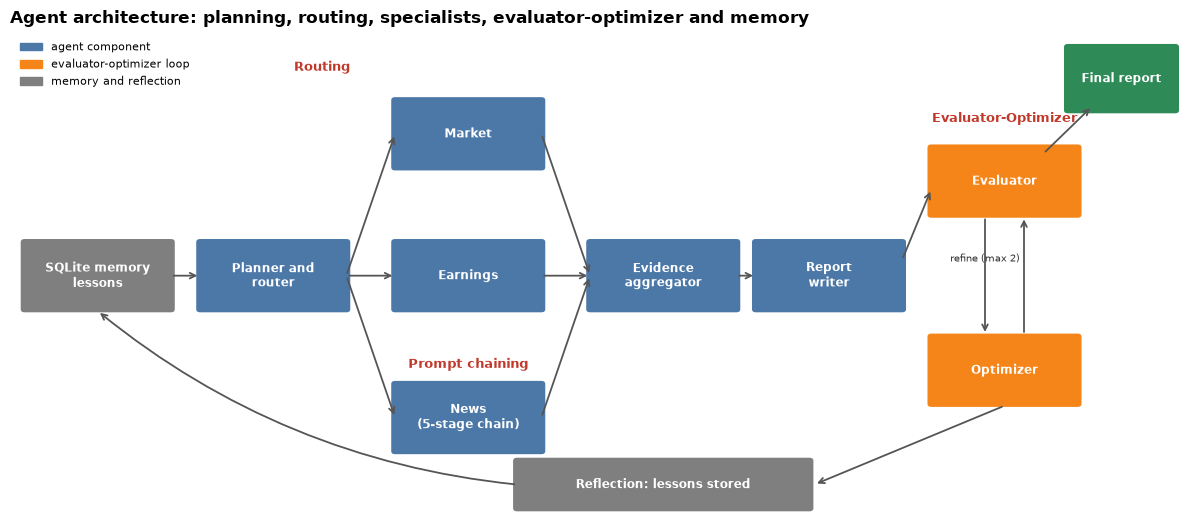

In [2]:
show(plot_agent_workflow(), 'architecture')

## 1. Planning

The planner reads the question and the lessons from memory, then asks the LLM for a structured plan: steps, the specialist for each step, the tools each step may use, dependencies and a completion criterion. Code validates the plan (known specialists, allowed tools, unique step IDs, no dependency cycles) before anything runs. If the LLM fails or returns an invalid plan, a keyword router takes over, so planning never stops the run.

Planner mode: llm | scope: comprehensive
Intent      : Conduct comprehensive investment research on MSFT covering financial fundamentals, market performance, and recent news catalysts.
Rationale   : The user requested comprehensive investment research for MSFT with no specific constraint, requiring fundamental, technical/market, and news-sentiment coverage across all available subagents.


,step,subagent,description,depends_on,tools,completion_criteria,status
0,S1,earnings_agent,"Analyze MSFT financial statements to assess revenue, margins, profitability, balance sheet strength, and f...",-,get_financial_statements,"Complete financial statement analysis covering revenue growth, margins, cash flow, and risk factors is del...",pending
1,S2,market_agent,"Evaluate MSFT stock price performance, rolling volatility, and benchmark comparison.",-,"get_price_history, get_benchmark_history","Historical price performance, benchmark comparison, and volatility metrics are reported.",pending
2,S3,news_agent,"Gather and synthesize recent news events, potential catalysts, and qualitative business risks for MSFT.",-,get_company_news,"Source-backed news summary detailing recent key events, catalysts, and risks is produced.",pending


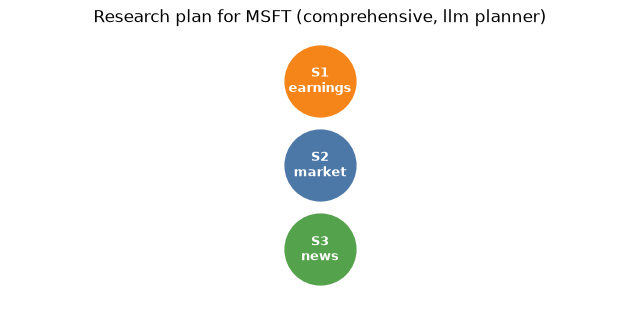

The llm planner produced 3 step(s) for a comprehensive question; the steps are independent and run in plan order.

In [3]:
plan_state = rt.orchestrator.plan('MSFT', 'Produce comprehensive investment research')
print('Planner mode:', plan_state.plan.planner_mode, '| scope:', plan_state.plan.scope)
print('Intent      :', plan_state.plan.intent)
print('Rationale   :', plan_state.plan.rationale)
display(plan_table(plan_state.plan))
show(plot_plan(plan_state.plan), 'plan', notes.plan(plan_state.plan))
for warning in plan_state.warnings:
    print('WARNING:', warning.source, '-', warning.message)

The planner ran in LLM mode and produced three independent steps, one per specialist, each limited to the tools that specialist needs. It added neither the macro nor the SEC filing tool, because the request did not ask for them.

## 2. Routing

Routing happens inside the planner. Six questions about the same stock show that the set of specialists changes with the question: narrow questions select one specialist, an earnings-and-price question selects two with earnings first, a macro question adds the optional macro tool, and only the comprehensive request selects all three.

Analyze one-year price performance
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
Analyze revenue and margin trends
   S1 earnings_agent: tools=['get_financial_statements']
Summarize recent product announcements
   S1 news_agent: tools=['get_company_news']
Analyze earnings and the resulting share-price movement
   S1 earnings_agent: tools=['get_financial_statements']
   S2 market_agent (after S1): tools=['get_price_history', 'get_benchmark_history']
Analyze price performance given interest rates and inflation
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history', 'get_macro_series']
Produce comprehensive investment research
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
   S2 earnings_agent: tools=['get_financial_statements']
   S3 news_agent: tools=['get_company_news']


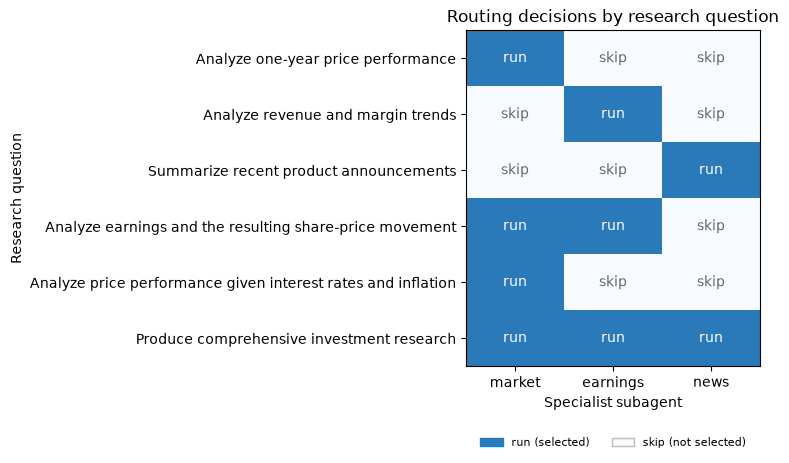

Across 6 questions the planner selected between 1 and 3 specialists. 4 question(s) needed a single specialist, and only 'Produce comprehensive investment research' used the most. Because the selection changes with the question, routing is conditional rather than a fixed pipeline.

In [4]:
QUESTIONS = [
    'Analyze one-year price performance',
    'Analyze revenue and margin trends',
    'Summarize recent product announcements',
    'Analyze earnings and the resulting share-price movement',
    'Analyze price performance given interest rates and inflation',
    'Produce comprehensive investment research',
]

cases = {}
for question in QUESTIONS:
    planned = rt.orchestrator.plan('AAPL', question)
    cases[question] = planned.routing_log
    print(question)
    for step in planned.plan.steps:
        dependency = f' (after {", ".join(step.depends_on)})' if step.depends_on else ''
        print(f'   {step.step_id} {step.subagent}{dependency}: tools={step.tools}')

show(plot_routing_matrix(cases, rt.subagents.names()), 'routing_matrix', notes.routing(cases))

In [5]:
# Selected and skipped specialists, each with a reason and a confidence.
display(routing_table(cases[QUESTIONS[3]]))
display(routing_table(cases[QUESTIONS[0]]))

,decision,subagent,task,reason,confidence,status
0,SELECTED,earnings_agent,"Retrieve and evaluate AAPL's recent earnings reports, key financial statements, and margin metrics.",Required to establish earnings release dates and financial performance figures.,0.95,pending
1,SELECTED,market_agent,"Assess AAPL's share-price movement, returns, and volatility surrounding the earnings announcement dates.",Directly answers the share-price movement component of the prompt using earnings dates from S1.,0.95,pending
2,skipped,news_agent,none,General company news is not needed to evaluate financial statements and share-price movements directly.,0.80,pending


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Retrieve and evaluate one-year historical price data, benchmark returns, trends, and rolling volatility fo...","Market agent specializes in stock price performance, comparative returns, and historical volatility trends.",0.95,pending
1,skipped,earnings_agent,none,Financial statement analysis and accounting metrics are outside the scope of price performance analysis.,0.80,pending
2,skipped,news_agent,none,Recent news headlines and catalysts are not requested for historical price performance metrics.,0.80,pending


The earnings-and-price question shows the one dependency in this set: the market step waits for the earnings step (S2 after S1). Only the interest-rate question received the optional macro tool. Every specialist the planner left out has a stated reason, and the confidence values range from 0.80 to 0.95.

## 3. Dynamic tool use and orchestration

The orchestrator runs the plan's steps in dependency order. Each specialist gets a tool session that allows only the tools named in its step, and every call is logged with its caller, status, duration and a short summary of the result. Memory reads and writes go through the same registry, so the log also shows when the agent retrieved lessons and when it stored new ones.

Two full runs follow: the comprehensive request and the narrow earnings-and-price question. Each run also writes and evaluates a report, refines it when needed, and reflects on itself; sections 7 to 10 look at those stages for the comprehensive run.

In [6]:
comprehensive = rt.orchestrator.run('MSFT', 'Produce comprehensive investment research')
narrow = rt.orchestrator.run('MSFT', 'Analyze earnings and the resulting share-price movement')


MEMORY_TOOLS = {'memory_retrieval', 'memory_storage'}


def tools_called(state, memory_tools=False):
    names = {call['tool_name'] for call in state.tool_call_log}
    return sorted(names & MEMORY_TOOLS if memory_tools else names - MEMORY_TOOLS)


display(pd.DataFrame({
    'question': [comprehensive.research_question, narrow.research_question],
    'specialists run': [', '.join(state.selected_subagents) for state in (comprehensive, narrow)],
    'data tools called': [', '.join(tools_called(state)) for state in (comprehensive, narrow)],
    'memory tools called': [', '.join(tools_called(state, memory_tools=True)) for state in (comprehensive, narrow)],
    'tool calls': [len(state.tool_call_log) for state in (comprehensive, narrow)],
}))
print('News tool called in the narrow run?', 'get_company_news' in tools_called(narrow))

,question,specialists run,data tools called,memory tools called,tool calls
0,Produce comprehensive investment research,"earnings_agent, market_agent, news_agent","get_benchmark_history, get_company_news, get_company_profile, get_financial_statements, get_price_history","memory_retrieval, memory_storage",7
1,Analyze earnings and the resulting share-price movement,"earnings_agent, market_agent","get_benchmark_history, get_company_profile, get_financial_statements, get_price_history","memory_retrieval, memory_storage",6


News tool called in the narrow run? False


,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,earnings_agent,success,2026-10-17T20:06:39+00:00,5.63,[get_financial_statements],1,"For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% year over year) and ne..."
1,S2,market_agent,success,2026-10-17T20:06:39+00:00,5.09,"[get_price_history, get_benchmark_history]",2,"MSFT returned +3.9% from 2025-10-17 to 2026-10-16 against +16.1% for SPY, with 33.0% annualized volatility..."


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,planner,memory_retrieval,success,1.51,1 records,None,2026-10-17T20:06:39+00:00
1,orchestrator,get_company_profile,success,0.30,dict with 13 keys,None,2026-10-17T20:06:39+00:00
2,earnings_agent,get_financial_statements,success,0.78,"DataFrame shape=(4, 9)",None,2026-10-17T20:06:39+00:00
3,market_agent,get_price_history,success,0.48,"DataFrame shape=(251, 5)",None,2026-10-17T20:06:39+00:00
4,market_agent,get_benchmark_history,success,0.45,"DataFrame shape=(251, 5)",None,2026-10-17T20:06:39+00:00
5,reflection,memory_storage,success,2.85,dict with 15 keys,None,2026-10-17T20:06:50+00:00


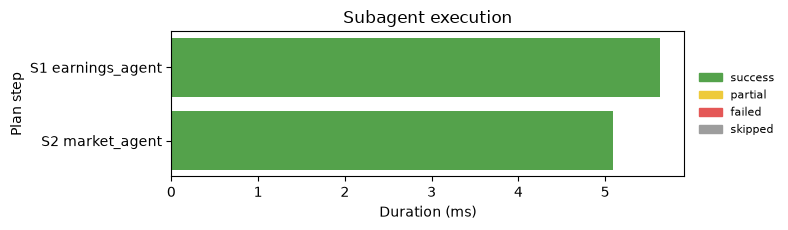

2 of 2 step(s) completed. The slowest was S1 earnings_agent at 0.0 s; cached data makes repeat runs of the data tools nearly instant.

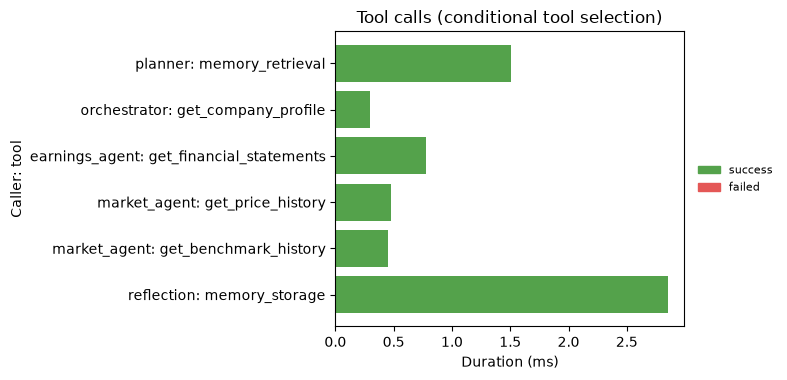

6 tool call(s) across 6 tool(s) (get_benchmark_history, get_company_profile, get_financial_statements, get_price_history, memory_retrieval, memory_storage); 0 failed. Each specialist could call only the tools its plan step listed, so tools the plan did not select never ran.

In [7]:
display(execution_table(narrow))
display(tool_log_table(narrow))
show(plot_execution_timeline(narrow), 'execution_narrow', notes.execution(narrow))
show(plot_tool_calls(narrow), 'tool_calls_narrow', notes.tool_calls(narrow))

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,earnings_agent,success,2026-10-17T20:04:53+00:00,7.72,[get_financial_statements],1,"For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% year over year) and ne..."
1,S2,market_agent,success,2026-10-17T20:04:53+00:00,4.28,"[get_price_history, get_benchmark_history]",2,"MSFT returned +3.9% from 2025-10-17 to 2026-10-16 against +16.1% for SPY, with 33.0% annualized volatility..."
2,S3,news_agent,success,2026-10-17T20:04:53+00:00,21.32,[get_company_news],1,"In product developments, Microsoft announced Maia 300, its next-generation custom AI chip [E1], and highli..."


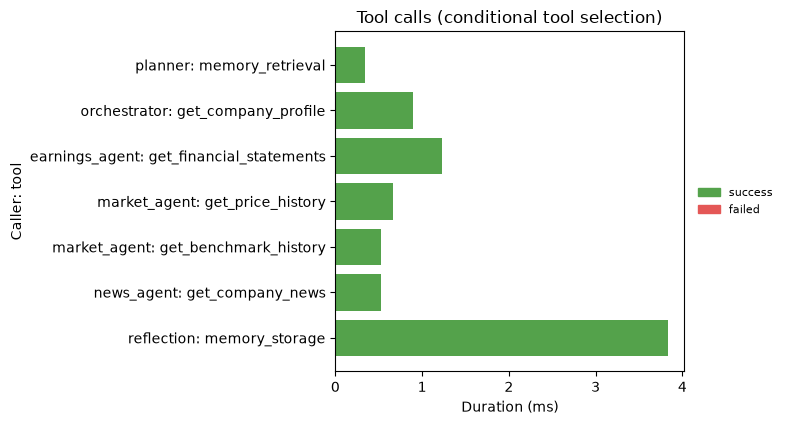

7 tool call(s) across 7 tool(s) (get_benchmark_history, get_company_news, get_company_profile, get_financial_statements, get_price_history, memory_retrieval, memory_storage); 0 failed. Each specialist could call only the tools its plan step listed, so tools the plan did not select never ran.

In [8]:
display(execution_table(comprehensive))
show(plot_tool_calls(comprehensive), 'tool_calls_comprehensive', notes.tool_calls(comprehensive))

The comprehensive run called five data tools and the narrow run four. The news tool never ran in the narrow run because its plan had no news step, and no specialist could call a tool its step did not list. Both runs also show memory_retrieval before planning and memory_storage after reflection, and none of the 13 tool calls failed.

## 4. Market and financial analysis

The market and earnings specialists compute everything in deterministic Python, so every number is reproducible and each finding cites the evidence IDs behind it (MKT-n, ERN-n). The charts come from the same data the specialists analysed.

Company : Microsoft Corporation | Technology | Software - Infrastructure | USD
Coverage: {'earnings_agent': 'success', 'market_agent': 'success', 'news_agent': 'success'}


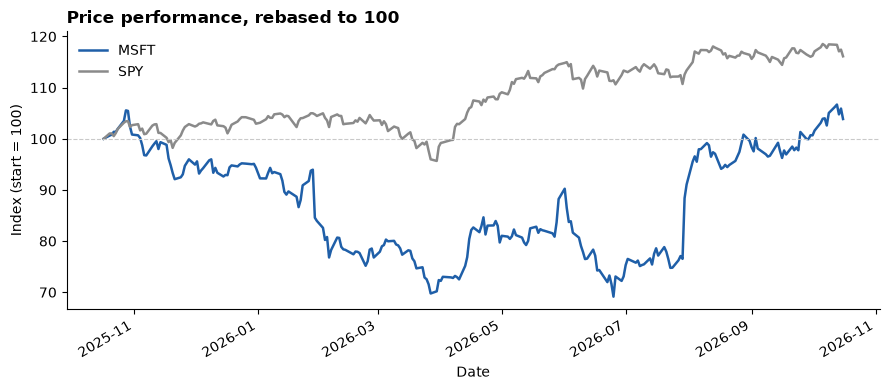

MSFT ended the window at 103.9, a +3.9% change since 2025-10-17, while SPY ended at 116.1 (+16.1%). The stock trailed the benchmark by 12.3 index points. Its lowest level was 69.1 on 2026-06-25, and the data ends on 2026-10-16.

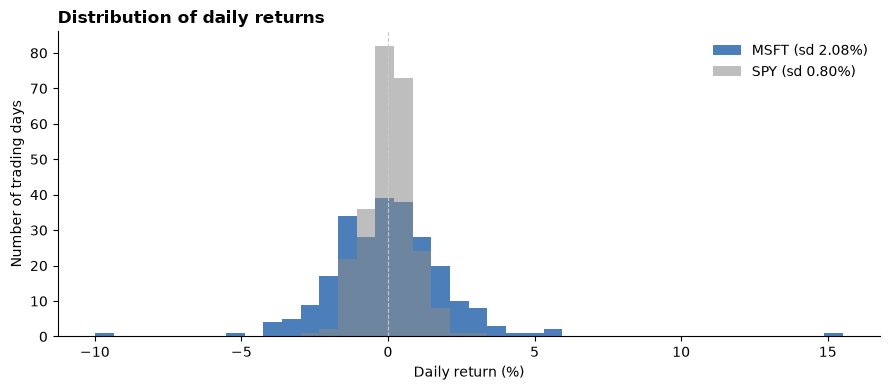

On a typical day MSFT moved about 2.08% (standard deviation of daily returns), and it closed higher on 50% of 250 trading days. The worst day was -9.99% on 2026-01-29 and the best +15.51% on 2026-07-30. Its daily moves were 2.6 times as wide as SPY's, so its histogram is the flatter of the two.

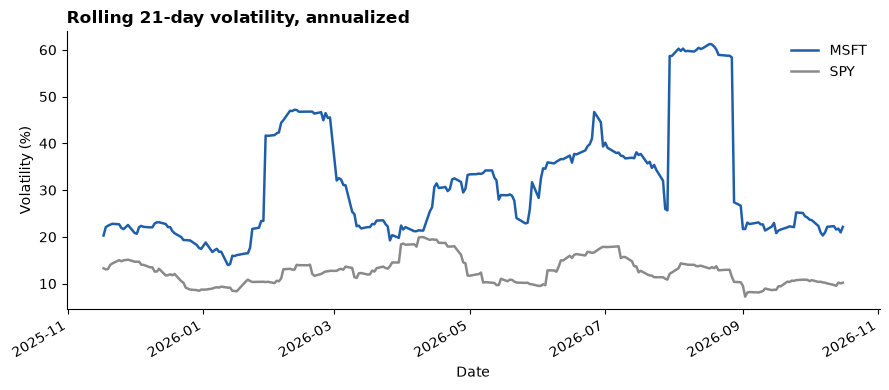

MSFT's 21-day annualised volatility averaged 31.3% and peaked at 61.3% on 2026-08-17; the latest reading is 22.1%, against an average of 12.6% for SPY.

,statement,evidence_ids
0,"MSFT returned +3.9% from 2025-10-17 to 2026-10-16 versus +16.1% for SPY, underperforming by 12.3 percentag...","[MKT-1, MKT-3, MKT-4]"
1,Annualized volatility was 33.0% versus 12.7% for SPY; beta was 1.00.,"[MKT-2, MKT-5, MKT-6]"
2,"Maximum drawdown was -34.5%, from the peak on 2025-10-28 to the trough on 2026-06-25.",[MKT-7]
3,"Trailing returns: 1M +6.3%, 3M +31.8%, 6M +25.6%.",[MKT-8]
4,The last close (529.05) is 4.7% above the 50-day moving average (505.37).,[MKT-9]
5,The last close (529.05) is 21.9% above the 200-day moving average (434.03).,[MKT-10]


In [9]:
profile = comprehensive.company_profile or {}
print('Company :', profile.get('name'), '|', profile.get('sector'), '|', profile.get('industry'), '|', profile.get('currency'))
print('Coverage:', comprehensive.aggregated['coverage'])
visuals = comprehensive.aggregated['visualization_data']
findings = pd.DataFrame(comprehensive.aggregated['findings'])
market = visuals.get('market_agent', {})
if 'performance' in market:
    show(plot_performance(market['performance']), 'performance', notes.performance(market['performance']))
    show(plot_daily_return_distribution(market['performance']), 'daily_returns', notes.daily_returns(market['performance']))
    show(plot_rolling_volatility(market['rolling_volatility'], SETTINGS.volatility_window), 'rolling_volatility',
         notes.volatility(market['rolling_volatility'], SETTINGS.volatility_window))
    display(findings[findings.agent == 'market_agent'][['statement', 'evidence_ids']])
else:
    print('Market data unavailable:', [w.message for w in comprehensive.warnings if w.source == 'market_agent'])

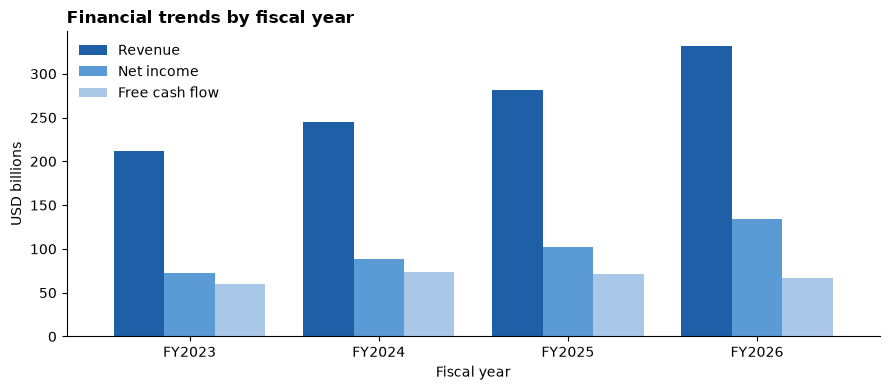

Revenue went from USD 211.9 bn in FY2023 to USD 331.8 bn in FY2026 (+57%); Net income went from USD 72.4 bn in FY2023 to USD 133.7 bn in FY2026 (+85%); Free cash flow went from USD 59.5 bn in FY2023 to USD 67.0 bn in FY2026 (+13%). The chart covers 4 fiscal years, FY2023 to FY2026.

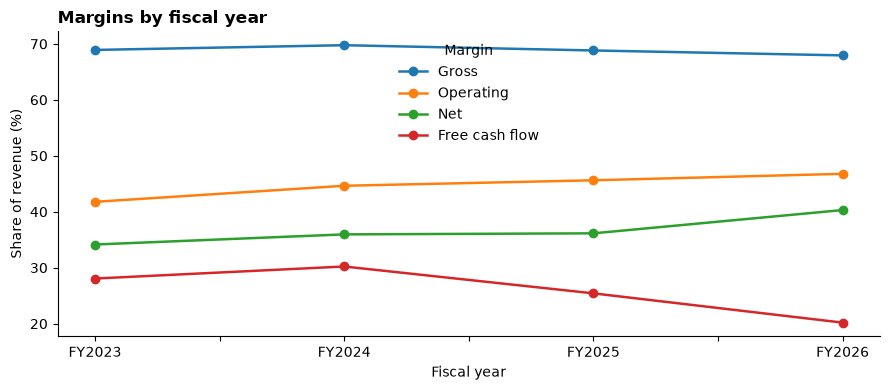

From FY2023 to FY2026: gross margin 68.9% to 67.9%; operating margin 41.8% to 46.8%; net margin 34.1% to 40.3%; free-cash-flow margin 28.1% to 20.2%.

,statement,evidence_ids
6,"Revenue for the fiscal year ended 2026-06-30 was USD 331.8 bn, +17.8% year over year (+16.1% CAGR since 20...","[ERN-1, ERN-2, ERN-3]"
7,Net income was USD 133.7 bn (+31.3% year over year); net margin was 40.3% versus 36.1% a year earlier.,"[ERN-4, ERN-5, ERN-6]"
8,Profitability: gross margin 67.9% (prior year 68.8%); operating margin 46.8% (prior year 45.6%).,"[ERN-7, ERN-8]"
9,Free cash flow was USD 67.0 bn (20.2% of revenue); operating cash flow was 1.37x net income.,"[ERN-9, ERN-10]"
10,Total debt was USD 56.8 bn against USD 20.9 bn of cash; debt-to-equity was 0.13x.,"[ERN-11, ERN-12, ERN-13]"


In [10]:
earnings = visuals.get('earnings_agent', {})
if 'financial_trends' in earnings:
    show(plot_financial_trends(earnings['financial_trends'], earnings['currency']), 'financial_trends',
         notes.financial_trends(earnings['financial_trends'], earnings['currency']))
    show(plot_margins(earnings['margins']), 'margins', notes.margins(earnings['margins']))
    display(findings[findings.agent == 'earnings_agent'][['statement', 'evidence_ids']])
else:
    print('Financial statements unavailable:', [w.message for w in comprehensive.warnings if w.source == 'earnings_agent'])

Over the year MSFT returned 3.9% against 16.1% for SPY, and the rebased price bottomed at 69.1 in June 2026, at the end of a 34.5% maximum drawdown that began in late October 2025. Its daily returns were about 2.6 times as dispersed as the benchmark's. The fundamentals tell a different story: revenue rose 17.8% to USD 331.8 bn in fiscal 2026 and net margin widened from 36.1% to 40.3%, while free cash flow grew only 13% over three years as its margin fell from 28.1% to 20.2%.

## 5. News prompt chain, stage by stage

The news specialist runs five stages in order, and each stage's output is kept so it can be inspected here. Ingest and preprocess are plain Python. Classify, extract and summarize call the LLM under JSON schemas, and code validates every answer: labels outside the allowed sets become `unknown`, extracted entities and figures must appear in the headline or its summary, and summary citations must name real events.

In [11]:
news = visuals.get('news_agent', {})
stages = news.get('stages', {})


def records(items):
    return pd.DataFrame([item.model_dump() if hasattr(item, 'model_dump') else item for item in items])


if not stages:
    print('News stages unavailable:', [w.message for w in comprehensive.warnings if w.source == 'news_agent'])
else:
    raw = records(stages['raw'])
    print(f"Stage 1, ingest: {len(raw)} headlines; feed errors: {stages['feed_errors'] or 'none'}")
    display(raw[['id', 'title', 'publisher', 'published_at', 'source_feed']].head(8))

Stage 1, ingest: 123 headlines; feed errors: none


,id,title,publisher,published_at,source_feed
0,A001,Microsoft (MSFT) Is Facing Fresh Regulatory Pressure,Simply Wall St.,2026-10-17 19:11:24+00:00,yahoo_finance
1,A002,"Apple, Nvidia each gave $25M to Trump's White House ballroom — but the president's own name is nowhere on ...",Moneywise,2026-10-17 15:00:00+00:00,yahoo_finance
2,A003,UBS resets Microsoft stock price target for investors,TheStreet,2026-10-17 14:37:00+00:00,yahoo_finance
3,A004,Here's How Microsoft's $175 Billion in Capital Expenditures Is Hurting Its Business,Motley Fool,2026-10-17 14:36:00+00:00,yahoo_finance
4,A005,BofA Warns AI Investors Could Lose Even If the Technology Works,24/7 Wall St.,2026-10-17 11:44:11+00:00,yahoo_finance
5,A006,What would superintelligence look and feel like?,Investing.com,2026-10-17 05:09:34+00:00,yahoo_finance
6,A007,Why You Should Think About Palantir Differently Now,Trefis,2026-10-17 02:50:36+00:00,yahoo_finance
7,A008,"Elon Musk’s Roadster, Nvidia’s Space AI Push, Nadella’s Security Warning: Mag 7 Voices This Week",Stocktwits,2026-10-17 02:46:45+00:00,yahoo_finance


Stage 2, preprocess: 12 distinct, relevant, recent stories kept for the LLM


,id,title,publisher,published_at,duplicate_count,also_reported_by
0,A033,"Microsoft announces Maia 300, its next-generation custom AI chip",Microsoft Source,2026-10-12 13:48:12+00:00,2,[]
1,A110,"The Trump administration is suspending Microsoft from a green card program, alleging fraud",AP News,2026-10-09 00:07:00+00:00,2,[NBC News]
2,A055,Microsoft Dynamics 365 CRM skills for Copilot and agentic workflows - Microsoft Dynamics 365 Blog,Microsoft,2026-10-08 07:00:00+00:00,2,[]
3,A097,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",Axios,2026-10-08 07:00:00+00:00,2,[CNBC]
4,A001,Microsoft (MSFT) Is Facing Fresh Regulatory Pressure,Simply Wall St.,2026-10-17 19:11:24+00:00,1,[]
5,A003,UBS resets Microsoft stock price target for investors,TheStreet,2026-10-17 14:37:00+00:00,1,[]
6,A004,Here's How Microsoft's $175 Billion in Capital Expenditures Is Hurting Its Business,Motley Fool,2026-10-17 14:36:00+00:00,1,[]
7,A010,"Not Alphabet. Not Microsoft. This Is the Cloud Stock I'd Buy With $5,000 Right Now.",Motley Fool,2026-10-16 21:43:00+00:00,1,[]
8,A011,Microsoft's UK Regulatory Problem Just Got Bigger,GuruFocus.com,2026-10-16 20:57:01+00:00,1,[]
9,A012,Microsoft Makes a Massive Move to Secure Its AI Future,GuruFocus.com,2026-10-16 20:56:18+00:00,1,[]


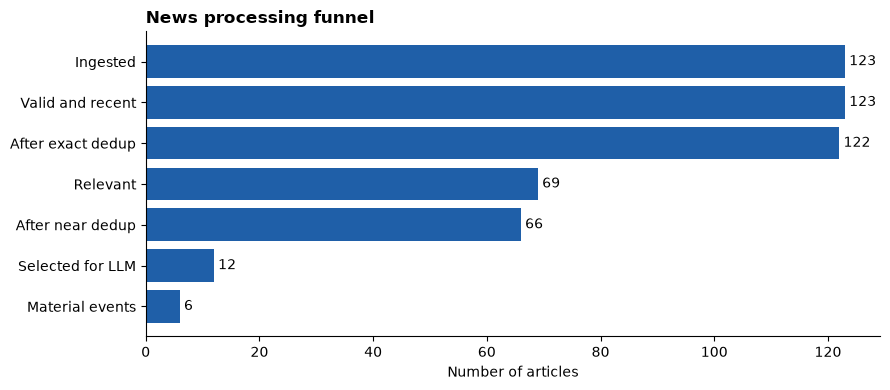

123 headlines came in from the feeds; 123 were recent and usable, 122 remained after exact duplicates were merged, 69 were about the company and 66 distinct stories were left after near duplicates were clustered. The 12 most widely covered and most recent stories (10% of the intake) went to the language model, which extracted 6 material events.

In [12]:
if stages:
    clean = records(stages['clean'])
    print(f'Stage 2, preprocess: {len(clean)} distinct, relevant, recent stories kept for the LLM')
    display(clean[['id', 'title', 'publisher', 'published_at', 'duplicate_count', 'also_reported_by']])
    show(plot_news_funnel(news['funnel']), 'news_funnel', notes.news_funnel(news['funnel']))

Stage 3, classify: event type, relevance, impact and time horizon for each story


,id,title,event_type,relevance,impact,time_horizon
0,A033,"Microsoft announces Maia 300, its next-generation custom AI chip",product,high,positive,medium_term
1,A110,"The Trump administration is suspending Microsoft from a green card program, alleging fraud",regulatory_legal,high,negative,medium_term
2,A055,Microsoft Dynamics 365 CRM skills for Copilot and agentic workflows - Microsoft Dynamics 365 Blog,product,medium,positive,medium_term
3,A097,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",regulatory_legal,high,negative,medium_term
4,A001,Microsoft (MSFT) Is Facing Fresh Regulatory Pressure,regulatory_legal,high,negative,medium_term
5,A003,UBS resets Microsoft stock price target for investors,analyst_rating,low,neutral,short_term
6,A004,Here's How Microsoft's $175 Billion in Capital Expenditures Is Hurting Its Business,market_commentary,low,negative,medium_term
7,A010,"Not Alphabet. Not Microsoft. This Is the Cloud Stock I'd Buy With $5,000 Right Now.",market_commentary,low,neutral,short_term
8,A011,Microsoft's UK Regulatory Problem Just Got Bigger,regulatory_legal,high,negative,medium_term
9,A012,Microsoft Makes a Massive Move to Secure Its AI Future,market_commentary,low,neutral,long_term


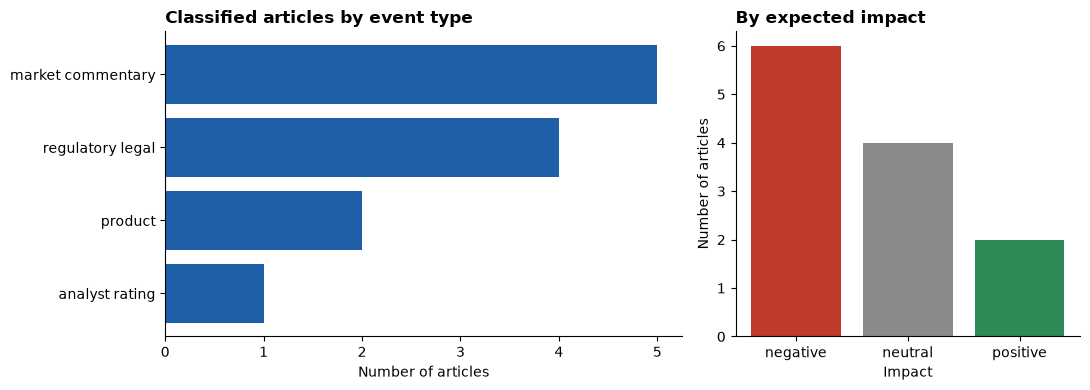

The most common event type was market commentary (5 of 12 classified headlines). By expected impact: 6 negative, 4 neutral, 2 positive. These labels are language-model judgements, not observed facts.

In [13]:
if stages:
    classified = records(stages['classified'])
    print('Stage 3, classify: event type, relevance, impact and time horizon for each story')
    display(classified[['id', 'title', 'event_type', 'relevance', 'impact', 'time_horizon']])
    categories = classified['event_type'].value_counts().to_dict()
    impacts = classified['impact'].value_counts().to_dict()
    show(plot_news_categories(categories, impacts), 'news_categories', notes.news_categories(categories, impacts))

In [14]:
if stages:
    events = records(stages['events'])
    print(f'Stage 4, extract: {len(events)} material events')
    display(events[['id', 'article_id', 'event', 'event_date', 'entities', 'figures', 'risks', 'catalysts', 'extraction_method']])

Stage 4, extract: 6 material events


,id,article_id,event,event_date,entities,figures,risks,catalysts,extraction_method
0,E1,A033,"Microsoft announced Maia 300, its next-generation custom AI chip.",2026-10-12,"[Microsoft, Maia 300]",[],"[Execution and manufacturing risks for custom hardware, Intense competition from established chipmakers]","[Lower AI infrastructure and compute costs, Reduced dependency on third-party chip suppliers]",llm
1,E2,A110,"The Trump administration is suspending Microsoft from a green card program, alleging fraud.",2026-10-09,"[Trump administration, Microsoft]",[],"[Talent recruitment and retention constraints, Reputational and regulatory fallout]",[],llm
2,E3,A097,"Trump's crackdown on foreign workers targets Microsoft, Adobe, and other IT firms.",2026-10-08,"[Trump, Microsoft, Adobe]",[],"[Restrictions on hiring foreign talent, Increased labor and operational costs]",[],llm
3,E4,A001,Microsoft is facing fresh regulatory pressure.,2026-10-17,"[Microsoft, MSFT]",[],"[Potential regulatory fines or penalties, Operational restrictions or compliance burdens]",[],llm
4,E5,A011,Microsoft faces increased regulatory problems in the UK.,2026-10-16,[Microsoft],[],"[Increased regulatory scrutiny in the UK, Risk of blocked deals or regulatory penalties]",[],llm
5,E6,A055,Microsoft highlighted Dynamics 365 CRM skills designed for Copilot and agentic workflows.,2026-10-08,"[Microsoft Dynamics 365 CRM, Copilot, Microsoft Dynamics 365 Blog]",[],"[Intensifying competition in AI-powered enterprise CRM solutions, Customer hesitation in adopting agentic ...","[Higher adoption of Microsoft Copilot and Dynamics 365, Increased enterprise software monetization through...",llm


In [15]:
if stages:
    summary = stages['summary']
    print('Stage 5, summarize (method:', summary['method'], '| cited events:', summary['cited_event_ids'], ')')
    print(summary['summary'])

Stage 5, summarize (method: llm | cited events: ['E1', 'E6', 'E3', 'E2', 'E4', 'E5'] )
In product developments, Microsoft announced Maia 300, its next-generation custom AI chip [E1], and highlighted Dynamics 365 CRM skills designed for Copilot and agentic workflows [E6]. Regarding government actions, Trump's crackdown on foreign workers targets Microsoft, Adobe, and other IT firms [E3]. In addition, the Trump administration is suspending Microsoft from a green card program, alleging fraud [E2]. The company is also facing fresh regulatory pressure [E4], alongside increased regulatory problems in the UK [E5]. Overall, the balance of recent developments is negative, as regulatory and legal challenges outnumber positive product announcements.


Preprocessing cut 123 headlines to 12 stories before any LLM call: only 69 were about Microsoft, and the cap kept the 12 most widely covered and most recent of the 66 distinct stories. The classifier rated six of the twelve negative, four of them regulatory, and marked the six market-commentary and analyst stories as low relevance, so extraction kept six material events. The summary cites all six events by ID; its closing view that regulatory news outweighs the product news is the model's judgement, not an observed fact.

## 6. Partial failure handling

The news specialist is replaced with one that raises an error. The market and earnings specialists still complete, and the failure becomes a warning, a limitation, an unavailable news section and lower confidence in the report, instead of invented content.

In [16]:
original_news_agent = rt.subagents.get('news_agent').fn


def failing_news_agent(state, tools, step):
    raise RuntimeError('simulated news API outage')


rt.subagents.attach('news_agent', failing_news_agent)
try:
    failed_run = rt.orchestrator.run('AAPL', 'Produce comprehensive investment research')
finally:
    rt.subagents.attach('news_agent', original_news_agent)

display(execution_table(failed_run)[['step_id', 'subagent', 'status', 'tool_calls', 'message']])
print('Coverage:', failed_run.aggregated['coverage'])
print('Errors  :', [w.message for w in failed_run.warnings if w.severity == 'error'])
failed_report = ResearchReport.from_dict(failed_run.final_report)
print('Report confidence:', failed_report.confidence['level'], '|', '; '.join(failed_report.confidence['reasons']))
for key in ('news_and_events', 'conflicting_or_missing_evidence'):
    section = failed_report.section(key)
    print(f'{section.title} ({section.status}): {section.note}')
    for statement in section.statements:
        print('   -', statement.render())

,step_id,subagent,status,tool_calls,message
0,S1,earnings_agent,success,1,"For the fiscal year ended 2025-09-30, AAPL reported revenue of USD 416.2 bn (+6.4% year over year) and net..."
1,S2,market_agent,success,2,"AAPL returned +36.6% from 2025-10-17 to 2026-10-16 against +16.1% for SPY, with 24.4% annualized volatilit..."
2,S3,news_agent,failed,0,RuntimeError: simulated news API outage


Coverage: {'earnings_agent': 'success', 'market_agent': 'success', 'news_agent': 'failed'}
Errors  : ['Subagent failed: RuntimeError: simulated news API outage']
Report confidence: low | based on 23 evidence items from 2 specialist(s); selected specialist(s) did not complete: news
News and events (unavailable): The news analysis was attempted but did not complete (failed), so no news findings are available.
Conflicting or missing evidence (complete): 
   - *Note:* The news analysis failed to complete, leaving qualitative developments and media coverage unexamined. [L5]
   - *Note:* Potential catalysts were not assessed because they depend on the unavailable news analysis. [L5]


With the news step failing, the market and earnings steps still completed with their own tool calls. The report marks the news section unavailable, explains the gap under limitation L5 in the conflicting or missing evidence section, notes that catalysts could not be assessed, and lowers its confidence to low.

## 7. Initial report

The report writer receives an evidence pack: the specialists' findings with their evidence IDs, numbered risks (R), catalysts (C) and limitations (L), and company-profile facts (PRO). The LLM writes a brief first draft, and every statement says whether it is a fact (which must cite evidence), an interpretation or a disclosure about the analysis itself. Citations to IDs that are not in the pack are removed before anything is scored. Code builds the company overview, the confidence level and the sources table, so those parts cannot be invented.

In [17]:
draft = ResearchReport.from_dict(comprehensive.draft_report)
statement_count = sum(len(section.statements) for section in draft.sections)
print(f'Writer: {draft.generated_by} | statements: {statement_count} | evidence items cited: {len(draft.cited_ids())}')
display(Markdown(draft.to_markdown(heading_level=3)))

Writer: llm | statements: 35 | evidence items cited: 30


### MSFT investment research report (version 0)

**Question:** Produce comprehensive investment research

Generated 2026-10-17T20:04:53+00:00 by the llm writer. Confidence: High.

> Educational research only. This is not personalised investment advice.

#### Executive summary

- Microsoft generated revenue of USD 331839000000.0 and net income of USD 133749000000.0 in the fiscal year ended 2026-06-30. [ERN-1, ERN-4]
- MSFT returned 3.86% between 2025-10-17 and 2026-10-16, underperforming SPY's 16.12% return by -12.26 percentage points. [MKT-1, MKT-3, MKT-4]
- *Interpretation:* Strong financial growth and AI chip innovation provide operational momentum, though regulatory pressures and workforce visa restrictions pose ongoing operational headwinds. [NEWS-1, NEWS-2, NEWS-4, R5, R6, C1]
- *Note:* This research analyzes annual financial statements through 2026-06-30, market prices through 2026-10-16, and recent headlines without providing investment advice. [L1, L3]

#### Company overview

- Microsoft Corporation (MSFT) is listed on the Nasdaq Global Select Market and quoted in USD. [PRO-1]
- Sector: Technology; industry: Software - Infrastructure. [PRO-2]
- Country: United States. [PRO-3]
- Market capitalisation was USD 3,928.5 bn when the profile was retrieved. [PRO-4]

#### Market performance

- MSFT returned 3.86% with annualized daily volatility of 32.96% from 2025-10-17 to 2026-10-16, compared to SPY's 16.12% return and 12.74% volatility. [MKT-1, MKT-2, MKT-3, MKT-5, R1]
- The stock registered a maximum drawdown of -34.5% between 2025-10-28 and 2026-06-25, before posting a 3-month trailing return of 31.76%. [MKT-7, MKT-8, R2]
- As of 2026-10-16, MSFT closed 4.69% above its 50-day moving average and 21.89% above its 200-day moving average. [MKT-9, MKT-10]
- *Interpretation:* The 6.29% 1-month gain occurred alongside positive product announcements like Maia 300, despite contemporaneous reports of government and regulatory scrutiny. [MKT-8, NEWS-1, NEWS-4, R6, C1]

#### Financial analysis

- Revenue for the fiscal year ended 2026-06-30 was USD 331839000000.0, up 17.79% year over year and reflecting a 16.12% CAGR since 2023-06-30. [ERN-1, ERN-2, ERN-3]
- Net income rose 31.34% year over year to USD 133749000000.0, with net margin improving to 40.31% from 36.15%. [ERN-4, ERN-5, ERN-6]
- Gross margin was 67.94% versus 68.82% in the prior year, while operating margin expanded to 46.78% from 45.62%. [ERN-7, ERN-8]
- Free cash flow reached USD 66987000000.0, supported by cash and equivalents of USD 20935000000.0 and a low debt-to-equity ratio of 0.13x. [ERN-9, ERN-12, ERN-13]

#### News and events

- Microsoft announced Maia 300, its next-generation custom AI chip, on 2026-10-12. [NEWS-1, R3, R4, C1, C2]
- The Trump administration moved to suspend Microsoft from a green card program alleging fraud, as part of a wider crackdown targeting foreign IT workers. [NEWS-2, NEWS-3, R5, R6, R7, R8]
- Microsoft highlighted new Dynamics 365 CRM skills designed for Copilot and agentic workflows on 2026-10-08. [NEWS-6, C3, C4]
- Microsoft faced reports of fresh regulatory pressure and heightened regulatory scrutiny in the UK between 2026-10-16 and 2026-10-17. [NEWS-4, NEWS-5, R6]

#### Macro context

_Not covered in this run: the question did not call for macroeconomic context._

#### Risks

- *Interpretation:* Annualized volatility of 32.96% and a historical drawdown of -34.5% indicate that MSFT can experience sharp periodic price swings. [MKT-2, MKT-7, R1, R2]
- *Interpretation:* Developing in-house chips like Maia 300 carries execution and manufacturing challenges alongside competition from entrenched silicon producers. [NEWS-1, R3, R4]
- *Interpretation:* Immigration suspensions and visa restrictions could impair recruitment of foreign specialized talent, potentially increasing labor and operational costs. [NEWS-2, NEWS-3, R5, R7, R8]
- *Interpretation:* Escalating regulatory investigations across the United States and the UK could produce reputational harm, operational constraints, or legal penalties. [NEWS-4, NEWS-5, R6]

#### Catalysts

- *Interpretation:* Deployment of the custom Maia 300 chip could lower AI infrastructure and compute costs across Microsoft's data centers. [NEWS-1, C1]
- *Interpretation:* In-house silicon development helps reduce long-term operational dependency on external third-party chip suppliers. [NEWS-1, C2]
- *Interpretation:* Embedding agentic workflows and CRM skills within Dynamics 365 may drive higher enterprise adoption of Copilot. [NEWS-6, C3]
- *Interpretation:* Enhanced agentic software capabilities provide an avenue for expanding monetized AI software tiers across corporate customer accounts. [NEWS-6, C4]

#### Conflicting or missing evidence

- *Note:* Financial statements cover the fiscal year ended 2026-06-30, leaving performance in subsequent quarters unobserved. [L3]
- *Note:* The available news evidence details product announcements and regulatory scrutiny only at headline level without providing financial figures or unit economics. [L5]
- *Interpretation:* Although trailing 3-month share returns rebounded 31.76%, recent regulatory news headlines were predominantly negative. [MKT-8, NEWS-2, NEWS-4, NEWS-5, R6]

#### Confidence and limitations

- Confidence: **High**. Based on 29 evidence items from 3 specialist(s); news labels (event type, impact, risks, catalysts) are language-model judgements.
- *Note:* Market calculations are based on adjusted daily closing prices from 2025-10-17 to 2026-10-16, and past returns do not predict future performance. [L1]
- *Note:* SPY reflects broad equity market behavior and may not capture specific trends within enterprise software and infrastructure peers. [L2]
- *Note:* Financial line items are standardized by Yahoo Finance and may differ from official company disclosures. [L4]
- *Note:* News analysis is limited to twelve headlines from the past 30 days, with categorization relying on language-model assessments. [L5, L6, L7]

#### Sources

| ID | Evidence | Source | As of | Retrieved |
|---|---|---|---|---|
| ERN-1 | Revenue, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-4 | Net income, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| MKT-1 | MSFT total return from 2025-10-17 to 2026-10-16 | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-3 | SPY total return from 2025-10-17 to 2026-10-16 | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-4 | MSFT excess return versus SPY | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| NEWS-1 | Microsoft announced Maia 300, its next-generation custom AI chip. | [Microsoft Source](https://news.google.com/rss/articles/CBMisAFBVV95cUxPakdkdHNRbVNsYU1IWUlxbFktVGtiSXM5MExVRkdidzZidTBPMzZhUUlvZFdzc25UM0lEdXVRcm9jMWl5VkplNFlyckxDU2tDd0ZWbHk0dy1Nd1MtU2hCSnhBUUtBYmlvM1N5VGMtQ0gzRDBGSTJaUGZNUmxoa1VaQkUxUFdneVNRT0FvQUJidjJndjdqUEVRYXBDQzZldWcxc2xqY2ZXM2U2c0xZQkpOQQ?oc=5) | 2026-10-12 | 2026-10-17T19:25:46+00:00 |
| NEWS-2 | The Trump administration is suspending Microsoft from a green card program, alleging fraud. | [AP News](https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX3V6Ny1yNlc1Ym4ydmx5NXY2UEJyak1mNVROdkRqOTNGY2kxT1BrQUwyYVRzSmlDNlVIa0xnenNUM2cyWjg2NTd0Rl9seW1JOVFuRHczVk93M2RkOWdDOUV0Sl90WjFJeEZEeWNTUFFvNkNkRU81alBOWlltQ1VN?oc=5) | 2026-10-09 | 2026-10-17T19:25:46+00:00 |
| NEWS-4 | Microsoft is facing fresh regulatory pressure. | [Simply Wall St.](https://finance.yahoo.com/technology/ai/articles/microsoft-msft-facing-fresh-regulatory-191124990.html) | 2026-10-17 | 2026-10-17T19:25:46+00:00 |
| PRO-1 | Microsoft Corporation (MSFT) is listed on the Nasdaq Global Select Market and quoted in USD | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-2 | Sector: Technology; industry: Software - Infrastructure | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-3 | Country: United States | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-4 | Market capitalisation | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| MKT-2 | MSFT annualized volatility of daily returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-5 | SPY annualized volatility of daily returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-7 | MSFT maximum drawdown (peak 2025-10-28, trough 2026-06-25) | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-8 | MSFT trailing returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-9 | MSFT last close relative to its 50-day moving average | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-10 | MSFT last close relative to its 200-day moving average | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| ERN-2 | Revenue growth versus the prior fiscal year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-3 | Revenue CAGR since 2023-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-5 | Net income growth versus the prior fiscal year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-6 | Net margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-7 | Gross margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-8 | Operating margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-9 | Free cash flow, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-12 | Cash and equivalents, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-13 | Debt-to-equity ratio | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| NEWS-3 | Trump's crackdown on foreign workers targets Microsoft, Adobe, and other IT firms. | [Axios](https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMczI1UjNTNmFPUkVfVHpCVzRZVjM1ZHFMQlBoV3I0a21LY1JLaW1QWDNPMVFSYnpDSm0wWW1pVUJyWFhFc1BLdUg2WTRXbUNLMkdDd01zN280U0EwamFyS0puZllkMFRQOHA0Q0l4Wjl0VjJmcml3Rmc3Zk12Tm9ndFlzclRRQzE2?oc=5) | 2026-10-08 | 2026-10-17T19:25:46+00:00 |
| NEWS-6 | Microsoft highlighted Dynamics 365 CRM skills designed for Copilot and agentic workflows. | [Microsoft](https://news.google.com/rss/articles/CBMi5gFBVV95cUxPNzM1TlpJdjhQZnpTN19VUWRKWkoybFhRSXJxUjEzYnVTM2M4N2l6ZHg4ZE9xN09ieWtVZDhZazBrMkFjMnlWVWFZR0R0dkplTFVtV00wZ0RSNldHQWExUFpsUnRIWGJKZVh2SHlKMWVKSUU3ZGxNVW9ndENLbEJnUVdVZ3F2TlpfOUVXaVZYSXZNa3lvc3N4cDFOVWgwelNEV1d3RHB1OTVIdjZUZWJFeHJqZE1QT3pFLWUwUlZacURSZ0ItdE1WNWFDZmpKODdxbnBsTWIwTUdiUWZpVXJUVHVoMDFPZw?oc=5) | 2026-10-08 | 2026-10-17T19:25:46+00:00 |
| NEWS-5 | Microsoft faces increased regulatory problems in the UK. | [GuruFocus.com](https://finance.yahoo.com/technology/articles/microsofts-uk-regulatory-problem-just-205701676.html) | 2026-10-16 | 2026-10-17T19:25:46+00:00 |


The first draft has 35 statements citing 30 evidence items, and every figure in it matches the evidence. Several figures are raw evidence values such as USD 331839000000.0, though, and the executive summary says MSFT underperformed SPY by -12.26 percentage points, a double negative.

## 8. Evaluation

The evaluator scores the draft on eight criteria. Seven are checked in code against the evidence pack: grounding (facts cite real evidence), completeness (sections filled, findings reflected, gaps and price drivers explained), numeric consistency (every number matches its cited evidence after unit conversion), source recency, risk coverage, catalyst coverage and uncertainty disclosure. Clarity is judged twice, by the LLM and by readability rules (unformatted figures, double negatives, long or repeated sentences), and the lower score counts. A report is accepted when the weighted score reaches the threshold of 80 and every criterion reaches the floor of 60; otherwise every issue comes with the section it belongs to and a concrete fix.

In [18]:
history = comprehensive.evaluation_history
first_evaluation = history[0]
print(f"Overall score {first_evaluation['overall_score']} (threshold {first_evaluation['threshold']:.0f}, floor {first_evaluation['floor']:.0f}) "
      f"| decision: {first_evaluation['decision']} | clarity judged by: {first_evaluation['judge_mode']}")
criteria = pd.DataFrame(first_evaluation['criteria'])
criteria['details'] = criteria['details'].map(lambda details: {k: v for k, v in details.items() if k != 'summary'})
display(criteria[['label', 'weight', 'score', 'details']])
issues = pd.DataFrame(first_evaluation['issues'])
if len(issues):
    display(issues[['criterion', 'section', 'severity', 'message', 'corrective_action']])
else:
    print('The evaluator found no issues in the first draft.')

Overall score 95.5 (threshold 80, floor 60) | decision: refine | clarity judged by: llm


,label,weight,score,details
0,Evidence grounding,20.0,100.0,"{'facts': 17, 'cited_facts': 17, 'data_sections_without_facts': []}"
1,Completeness,15.0,100.0,"{'sections': 1.0, 'findings': 1.0, 'gaps': 1.0, 'drivers': 1.0}"
2,Numeric consistency,15.0,100.0,"{'numbers_checked': 30, 'numbers_matched': 30}"
3,Source recency,10.0,100.0,"{'cited_items_dated': 51, 'stale_items': [], 'sections_stating_period': '3/3'}"
4,Risk coverage,10.0,100.0,"{'items': 8, 'covered': 8}"
5,Catalyst coverage,10.0,100.0,"{'items': 4, 'covered': 4}"
6,Clarity,10.0,55.0,"{'judge_mode': 'llm', 'llm_score_1_to_5': 4, 'rule_score': 55.0}"
7,Uncertainty disclosure,10.0,100.0,"{'limitations': 7, 'disclosed': 7, 'overclaims': 0}"


,criterion,section,severity,message,corrective_action
0,clarity,executive_summary,low,"Unformatted, twelve-digit numbers with trailing decimals ('USD 331839000000.0' and 'USD 133749000000.0') m...","Format the values into billions, such as 'USD 331.8 billion' and 'USD 133.7 billion'."
1,clarity,executive_summary,low,The phrase 'underperforming SPY's 16.12% return by -12.26 percentage points' creates an awkward double neg...,Rephrase to 'underperforming SPY's 16.12% return by 12.26 percentage points' or 'lagging SPY by 12.26 perc...
2,clarity,financial_analysis,low,"Multiple large figures are written out as raw numbers with decimal points (e.g., 'USD 66987000000.0' and '...","Express these figures in billions, such as 'USD 67.0 billion' and 'USD 20.9 billion'."
3,clarity,catalysts,low,The term 'agentic workflows' is specialized AI industry jargon that may be unfamiliar to a general audience.,"Replace or clarify the term with plain language, such as 'automated AI agent tasks' or 'autonomous AI soft..."
4,clarity,executive_summary,medium,"Unformatted figure 331839000000.0 is hard to read: ""Microsoft generated revenue of USD 331839000000.0 and ...","Write large amounts in billions with one decimal (for example USD 331.8 bn), as the specialist findings do."
5,clarity,financial_analysis,medium,"Unformatted figure 331839000000 is hard to read: ""Revenue for the fiscal year ended 2026-06-30 was USD 331...","Write large amounts in billions with one decimal (for example USD 331.8 bn), as the specialist findings do."
6,clarity,financial_analysis,medium,"Unformatted figure 133749000000 is hard to read: ""Net income rose 31.34% year over year to USD 13374900000...","Write large amounts in billions with one decimal (for example USD 331.8 bn), as the specialist findings do."
7,clarity,financial_analysis,medium,"Unformatted figure 66987000000 is hard to read: ""Free cash flow reached USD 66987000000.0, supported by ca...","Write large amounts in billions with one decimal (for example USD 331.8 bn), as the specialist findings do."
8,clarity,executive_summary,low,"Double negative: ""MSFT returned 3.86% between 2025-10-17 and 2026-10-16, underperforming SPY's 16.12% retu...","State the gap as a positive number after the word that gives its direction, for example ""trailed SPY by 12..."


Seven criteria scored 100. Clarity scored 55: the LLM judge rated the prose 4 of 5, but the readability rules found four unformatted figures and one double negative, and clarity takes the lower of the two scores. Clarity is below the floor of 60, so the decision is to refine even though the overall score is 95.5.

## 9. Optimization and the refined report

The optimizer rewrites only the sections that have issues. The LLM receives each weak section with its issues, fixes and the IDs it may cite, and statements that already passed every check are locked: the LLM is asked to keep them word for word, and if a rewrite still drops any of their evidence, risk or limitation IDs, the original statement is put back. The evaluator then scores the new version. The loop stops when the report is accepted, after two refinement cycles, or when a cycle gains less than two points, and the best-scoring version becomes the final report.

,cycle,version,overall score,decision,issues,stop reason
0,0,0,95.5,refine,9,
1,1,1,97.5,accept,3,accepted: score met the threshold with no criterion below the floor


,version,section,method,issues
0,1,financial_analysis,llm,4
1,1,executive_summary,llm,4
2,1,catalysts,llm,1


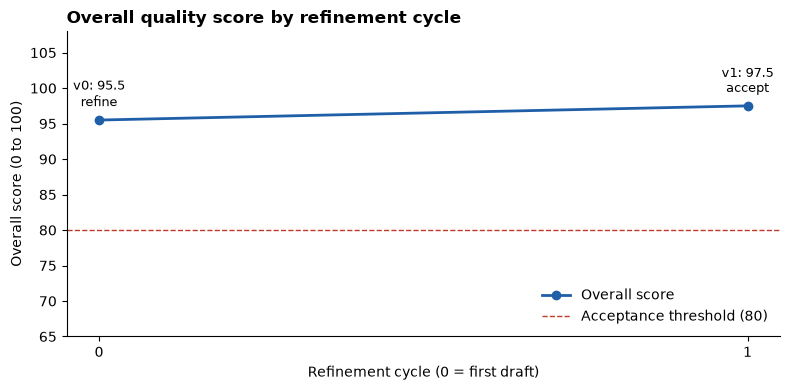

The first draft scored 95.5 against a threshold of 80. After 1 refinement cycle(s) the best version (v1) scored 97.5; the loop accepted: score met the threshold with no criterion below the floor.

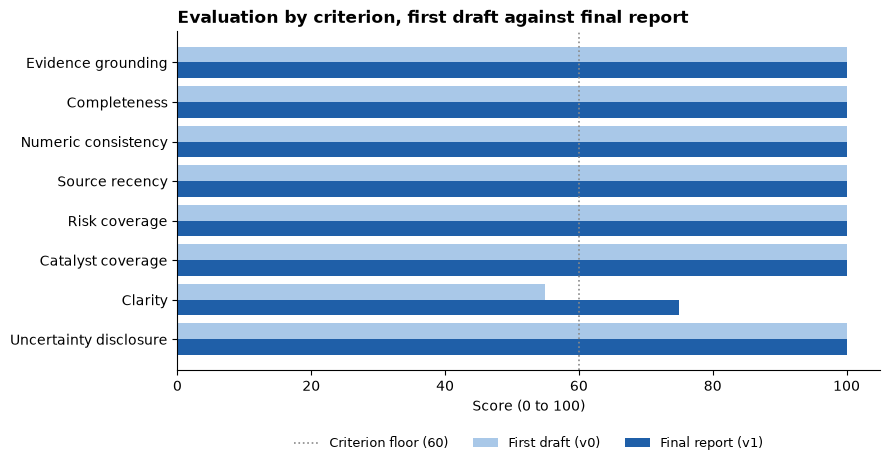

Refinement raised Clarity 55 to 75. The weakest criterion in the final report is clarity at 75/100.

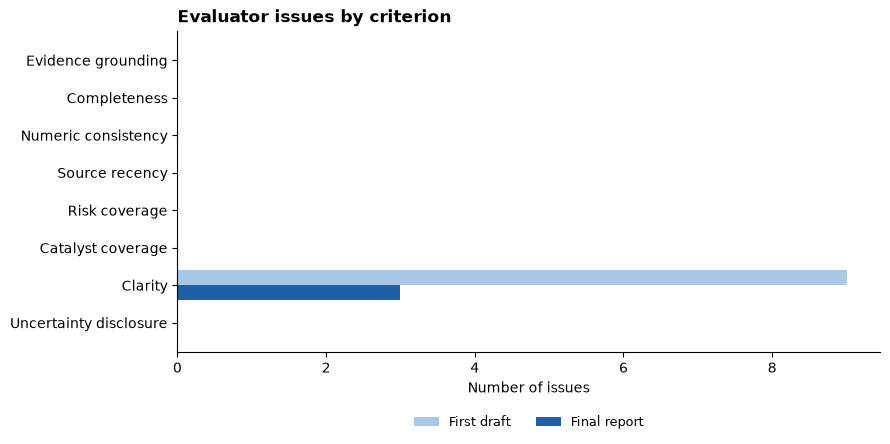

The first draft had 9 issue(s) and the final report has 3.

In [19]:
display(pd.DataFrame([{
    'cycle': h['cycle'], 'version': h['report_version'], 'overall score': h['overall_score'], 'decision': h['decision'],
    'issues': len(h['issues']), 'stop reason': h['stop_reason'],
} for h in history]))
final = ResearchReport.from_dict(comprehensive.final_report)
best = max(history, key=lambda h: h['overall_score'])
latest = ResearchReport.from_dict(history[-1]['report'])  # the last version the loop produced
if len(history) == 1:
    print('The first draft was accepted, so no section was refined.')
else:
    display(pd.DataFrame(latest.revisions))
    if latest.version != final.version:
        print(f'Version {latest.version} scored lower than version {final.version}, so the loop kept version {final.version} as the final report.')
show(plot_score_by_cycle(history), 'score_by_cycle', notes.score_by_cycle(history))
show(plot_criterion_scores(history[0], best), 'criteria_before_after', notes.criterion_scores(history[0], best))
show(plot_issue_counts(history[0], best), 'issues_before_after',
     f"The first draft had {len(history[0]['issues'])} issue(s) and the final report has {len(best['issues'])}.")

In [20]:
# Before and after for every section the optimizer rewrote.
order = [section.key for section in latest.sections]
for key in sorted({revision['section'] for revision in latest.revisions}, key=order.index):
    before, after = draft.section(key), latest.section(key)
    lines = [f'#### {after.title}', '', 'First draft:', '']
    lines += [f'- {statement.render()}' for statement in before.statements] or ['- (empty)']
    lines += ['', f'Version {latest.version}:', '']
    lines += [f'- {statement.render()}' for statement in after.statements]
    display(Markdown('\n'.join(lines)))

#### Executive summary

First draft:

- Microsoft generated revenue of USD 331839000000.0 and net income of USD 133749000000.0 in the fiscal year ended 2026-06-30. [ERN-1, ERN-4]
- MSFT returned 3.86% between 2025-10-17 and 2026-10-16, underperforming SPY's 16.12% return by -12.26 percentage points. [MKT-1, MKT-3, MKT-4]
- *Interpretation:* Strong financial growth and AI chip innovation provide operational momentum, though regulatory pressures and workforce visa restrictions pose ongoing operational headwinds. [NEWS-1, NEWS-2, NEWS-4, R5, R6, C1]
- *Note:* This research analyzes annual financial statements through 2026-06-30, market prices through 2026-10-16, and recent headlines without providing investment advice. [L1, L3]

Version 1:

- Microsoft generated revenue of USD 331.8 billion and net income of USD 133.7 billion in the fiscal year ended 2026-06-30. [ERN-1, ERN-4]
- MSFT returned 3.86% between 2025-10-17 and 2026-10-16, underperforming SPY's 16.12% return by 12.26 percentage points. [MKT-1, MKT-3, MKT-4]
- *Interpretation:* Strong financial growth and AI chip innovation provide operational momentum, though regulatory pressures and workforce visa restrictions pose ongoing operational headwinds. [NEWS-1, NEWS-2, NEWS-4, R5, R6, C1]
- *Note:* This research analyzes annual financial statements through 2026-06-30, market prices through 2026-10-16, and recent headlines without providing investment advice. [L1, L3]

#### Financial analysis

First draft:

- Revenue for the fiscal year ended 2026-06-30 was USD 331839000000.0, up 17.79% year over year and reflecting a 16.12% CAGR since 2023-06-30. [ERN-1, ERN-2, ERN-3]
- Net income rose 31.34% year over year to USD 133749000000.0, with net margin improving to 40.31% from 36.15%. [ERN-4, ERN-5, ERN-6]
- Gross margin was 67.94% versus 68.82% in the prior year, while operating margin expanded to 46.78% from 45.62%. [ERN-7, ERN-8]
- Free cash flow reached USD 66987000000.0, supported by cash and equivalents of USD 20935000000.0 and a low debt-to-equity ratio of 0.13x. [ERN-9, ERN-12, ERN-13]

Version 1:

- Revenue for the fiscal year ended 2026-06-30 was USD 331.8 billion, up 17.79% year over year and reflecting a 16.12% CAGR since 2023-06-30. [ERN-1, ERN-2, ERN-3]
- Net income rose 31.34% year over year to USD 133.7 billion, with net margin improving to 40.31% from 36.15%. [ERN-4, ERN-5, ERN-6]
- Gross margin was 67.94% versus 68.82% in the prior year, while operating margin expanded to 46.78% from 45.62%. [ERN-7, ERN-8]
- Free cash flow reached USD 67.0 billion, supported by cash and equivalents of USD 20.9 billion and a low debt-to-equity ratio of 0.13x. [ERN-9, ERN-12, ERN-13]

#### Catalysts

First draft:

- *Interpretation:* Deployment of the custom Maia 300 chip could lower AI infrastructure and compute costs across Microsoft's data centers. [NEWS-1, C1]
- *Interpretation:* In-house silicon development helps reduce long-term operational dependency on external third-party chip suppliers. [NEWS-1, C2]
- *Interpretation:* Embedding agentic workflows and CRM skills within Dynamics 365 may drive higher enterprise adoption of Copilot. [NEWS-6, C3]
- *Interpretation:* Enhanced agentic software capabilities provide an avenue for expanding monetized AI software tiers across corporate customer accounts. [NEWS-6, C4]

Version 1:

- *Interpretation:* Deployment of the custom Maia 300 chip could lower AI infrastructure and compute costs across Microsoft's data centers. [NEWS-1, C1]
- *Interpretation:* In-house silicon development helps reduce long-term operational dependency on external third-party chip suppliers. [NEWS-1, C2]
- *Interpretation:* Embedding agentic workflows and CRM skills within Dynamics 365 may drive higher enterprise adoption of Copilot. [NEWS-6, C3]
- *Interpretation:* In this context, agentic workflows refer to automated AI agent tasks and autonomous software tools that execute complex business operations. [NEWS-6, C3]
- *Interpretation:* Enhanced agentic software capabilities provide an avenue for expanding monetized AI software tiers across corporate customer accounts. [NEWS-6, C4]

In [21]:
display(Markdown(final.to_markdown(heading_level=3)))

### MSFT investment research report (version 1)

**Question:** Produce comprehensive investment research

Generated 2026-10-17T20:04:53+00:00 by the llm writer. Confidence: High.

> Educational research only. This is not personalised investment advice.

#### Executive summary

- Microsoft generated revenue of USD 331.8 billion and net income of USD 133.7 billion in the fiscal year ended 2026-06-30. [ERN-1, ERN-4]
- MSFT returned 3.86% between 2025-10-17 and 2026-10-16, underperforming SPY's 16.12% return by 12.26 percentage points. [MKT-1, MKT-3, MKT-4]
- *Interpretation:* Strong financial growth and AI chip innovation provide operational momentum, though regulatory pressures and workforce visa restrictions pose ongoing operational headwinds. [NEWS-1, NEWS-2, NEWS-4, R5, R6, C1]
- *Note:* This research analyzes annual financial statements through 2026-06-30, market prices through 2026-10-16, and recent headlines without providing investment advice. [L1, L3]

#### Company overview

- Microsoft Corporation (MSFT) is listed on the Nasdaq Global Select Market and quoted in USD. [PRO-1]
- Sector: Technology; industry: Software - Infrastructure. [PRO-2]
- Country: United States. [PRO-3]
- Market capitalisation was USD 3,928.5 bn when the profile was retrieved. [PRO-4]

#### Market performance

- MSFT returned 3.86% with annualized daily volatility of 32.96% from 2025-10-17 to 2026-10-16, compared to SPY's 16.12% return and 12.74% volatility. [MKT-1, MKT-2, MKT-3, MKT-5, R1]
- The stock registered a maximum drawdown of -34.5% between 2025-10-28 and 2026-06-25, before posting a 3-month trailing return of 31.76%. [MKT-7, MKT-8, R2]
- As of 2026-10-16, MSFT closed 4.69% above its 50-day moving average and 21.89% above its 200-day moving average. [MKT-9, MKT-10]
- *Interpretation:* The 6.29% 1-month gain occurred alongside positive product announcements like Maia 300, despite contemporaneous reports of government and regulatory scrutiny. [MKT-8, NEWS-1, NEWS-4, R6, C1]

#### Financial analysis

- Revenue for the fiscal year ended 2026-06-30 was USD 331.8 billion, up 17.79% year over year and reflecting a 16.12% CAGR since 2023-06-30. [ERN-1, ERN-2, ERN-3]
- Net income rose 31.34% year over year to USD 133.7 billion, with net margin improving to 40.31% from 36.15%. [ERN-4, ERN-5, ERN-6]
- Gross margin was 67.94% versus 68.82% in the prior year, while operating margin expanded to 46.78% from 45.62%. [ERN-7, ERN-8]
- Free cash flow reached USD 67.0 billion, supported by cash and equivalents of USD 20.9 billion and a low debt-to-equity ratio of 0.13x. [ERN-9, ERN-12, ERN-13]

#### News and events

- Microsoft announced Maia 300, its next-generation custom AI chip, on 2026-10-12. [NEWS-1, R3, R4, C1, C2]
- The Trump administration moved to suspend Microsoft from a green card program alleging fraud, as part of a wider crackdown targeting foreign IT workers. [NEWS-2, NEWS-3, R5, R6, R7, R8]
- Microsoft highlighted new Dynamics 365 CRM skills designed for Copilot and agentic workflows on 2026-10-08. [NEWS-6, C3, C4]
- Microsoft faced reports of fresh regulatory pressure and heightened regulatory scrutiny in the UK between 2026-10-16 and 2026-10-17. [NEWS-4, NEWS-5, R6]

#### Macro context

_Not covered in this run: the question did not call for macroeconomic context._

#### Risks

- *Interpretation:* Annualized volatility of 32.96% and a historical drawdown of -34.5% indicate that MSFT can experience sharp periodic price swings. [MKT-2, MKT-7, R1, R2]
- *Interpretation:* Developing in-house chips like Maia 300 carries execution and manufacturing challenges alongside competition from entrenched silicon producers. [NEWS-1, R3, R4]
- *Interpretation:* Immigration suspensions and visa restrictions could impair recruitment of foreign specialized talent, potentially increasing labor and operational costs. [NEWS-2, NEWS-3, R5, R7, R8]
- *Interpretation:* Escalating regulatory investigations across the United States and the UK could produce reputational harm, operational constraints, or legal penalties. [NEWS-4, NEWS-5, R6]

#### Catalysts

- *Interpretation:* Deployment of the custom Maia 300 chip could lower AI infrastructure and compute costs across Microsoft's data centers. [NEWS-1, C1]
- *Interpretation:* In-house silicon development helps reduce long-term operational dependency on external third-party chip suppliers. [NEWS-1, C2]
- *Interpretation:* Embedding agentic workflows and CRM skills within Dynamics 365 may drive higher enterprise adoption of Copilot. [NEWS-6, C3]
- *Interpretation:* In this context, agentic workflows refer to automated AI agent tasks and autonomous software tools that execute complex business operations. [NEWS-6, C3]
- *Interpretation:* Enhanced agentic software capabilities provide an avenue for expanding monetized AI software tiers across corporate customer accounts. [NEWS-6, C4]

#### Conflicting or missing evidence

- *Note:* Financial statements cover the fiscal year ended 2026-06-30, leaving performance in subsequent quarters unobserved. [L3]
- *Note:* The available news evidence details product announcements and regulatory scrutiny only at headline level without providing financial figures or unit economics. [L5]
- *Interpretation:* Although trailing 3-month share returns rebounded 31.76%, recent regulatory news headlines were predominantly negative. [MKT-8, NEWS-2, NEWS-4, NEWS-5, R6]

#### Confidence and limitations

- Confidence: **High**. Based on 29 evidence items from 3 specialist(s); news labels (event type, impact, risks, catalysts) are language-model judgements.
- *Note:* Market calculations are based on adjusted daily closing prices from 2025-10-17 to 2026-10-16, and past returns do not predict future performance. [L1]
- *Note:* SPY reflects broad equity market behavior and may not capture specific trends within enterprise software and infrastructure peers. [L2]
- *Note:* Financial line items are standardized by Yahoo Finance and may differ from official company disclosures. [L4]
- *Note:* News analysis is limited to twelve headlines from the past 30 days, with categorization relying on language-model assessments. [L5, L6, L7]

#### Sources

| ID | Evidence | Source | As of | Retrieved |
|---|---|---|---|---|
| ERN-1 | Revenue, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-4 | Net income, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| MKT-1 | MSFT total return from 2025-10-17 to 2026-10-16 | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-3 | SPY total return from 2025-10-17 to 2026-10-16 | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-4 | MSFT excess return versus SPY | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| NEWS-1 | Microsoft announced Maia 300, its next-generation custom AI chip. | [Microsoft Source](https://news.google.com/rss/articles/CBMisAFBVV95cUxPakdkdHNRbVNsYU1IWUlxbFktVGtiSXM5MExVRkdidzZidTBPMzZhUUlvZFdzc25UM0lEdXVRcm9jMWl5VkplNFlyckxDU2tDd0ZWbHk0dy1Nd1MtU2hCSnhBUUtBYmlvM1N5VGMtQ0gzRDBGSTJaUGZNUmxoa1VaQkUxUFdneVNRT0FvQUJidjJndjdqUEVRYXBDQzZldWcxc2xqY2ZXM2U2c0xZQkpOQQ?oc=5) | 2026-10-12 | 2026-10-17T19:25:46+00:00 |
| NEWS-2 | The Trump administration is suspending Microsoft from a green card program, alleging fraud. | [AP News](https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX3V6Ny1yNlc1Ym4ydmx5NXY2UEJyak1mNVROdkRqOTNGY2kxT1BrQUwyYVRzSmlDNlVIa0xnenNUM2cyWjg2NTd0Rl9seW1JOVFuRHczVk93M2RkOWdDOUV0Sl90WjFJeEZEeWNTUFFvNkNkRU81alBOWlltQ1VN?oc=5) | 2026-10-09 | 2026-10-17T19:25:46+00:00 |
| NEWS-4 | Microsoft is facing fresh regulatory pressure. | [Simply Wall St.](https://finance.yahoo.com/technology/ai/articles/microsoft-msft-facing-fresh-regulatory-191124990.html) | 2026-10-17 | 2026-10-17T19:25:46+00:00 |
| PRO-1 | Microsoft Corporation (MSFT) is listed on the Nasdaq Global Select Market and quoted in USD | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-2 | Sector: Technology; industry: Software - Infrastructure | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-3 | Country: United States | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| PRO-4 | Market capitalisation | [Yahoo Finance (yfinance)](https://www.microsoft.com) | n/a | 2026-10-17T19:25:43+00:00 |
| MKT-2 | MSFT annualized volatility of daily returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-5 | SPY annualized volatility of daily returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-7 | MSFT maximum drawdown (peak 2025-10-28, trough 2026-06-25) | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-8 | MSFT trailing returns | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-9 | MSFT last close relative to its 50-day moving average | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| MKT-10 | MSFT last close relative to its 200-day moving average | Yahoo Finance (yfinance) | 2026-10-16 | 2026-10-17T19:25:43+00:00 |
| ERN-2 | Revenue growth versus the prior fiscal year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-3 | Revenue CAGR since 2023-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-5 | Net income growth versus the prior fiscal year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-6 | Net margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-7 | Gross margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-8 | Operating margin, latest versus prior year | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-9 | Free cash flow, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-12 | Cash and equivalents, fiscal year ended 2026-06-30 | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| ERN-13 | Debt-to-equity ratio | Yahoo Finance (yfinance) | 2026-06-30 | 2026-10-17T19:25:44+00:00 |
| NEWS-3 | Trump's crackdown on foreign workers targets Microsoft, Adobe, and other IT firms. | [Axios](https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMczI1UjNTNmFPUkVfVHpCVzRZVjM1ZHFMQlBoV3I0a21LY1JLaW1QWDNPMVFSYnpDSm0wWW1pVUJyWFhFc1BLdUg2WTRXbUNLMkdDd01zN280U0EwamFyS0puZllkMFRQOHA0Q0l4Wjl0VjJmcml3Rmc3Zk12Tm9ndFlzclRRQzE2?oc=5) | 2026-10-08 | 2026-10-17T19:25:46+00:00 |
| NEWS-6 | Microsoft highlighted Dynamics 365 CRM skills designed for Copilot and agentic workflows. | [Microsoft](https://news.google.com/rss/articles/CBMi5gFBVV95cUxPNzM1TlpJdjhQZnpTN19VUWRKWkoybFhRSXJxUjEzYnVTM2M4N2l6ZHg4ZE9xN09ieWtVZDhZazBrMkFjMnlWVWFZR0R0dkplTFVtV00wZ0RSNldHQWExUFpsUnRIWGJKZVh2SHlKMWVKSUU3ZGxNVW9ndENLbEJnUVdVZ3F2TlpfOUVXaVZYSXZNa3lvc3N4cDFOVWgwelNEV1d3RHB1OTVIdjZUZWJFeHJqZE1QT3pFLWUwUlZacURSZ0ItdE1WNWFDZmpKODdxbnBsTWIwTUdiUWZpVXJUVHVoMDFPZw?oc=5) | 2026-10-08 | 2026-10-17T19:25:46+00:00 |
| NEWS-5 | Microsoft faces increased regulatory problems in the UK. | [GuruFocus.com](https://finance.yahoo.com/technology/articles/microsofts-uk-regulatory-problem-just-205701676.html) | 2026-10-16 | 2026-10-17T19:25:46+00:00 |


One cycle rewrote the executive summary, the financial analysis and the catalysts. The figures now read USD 331.8 billion, the gap reads 12.26 percentage points, and a new bullet explains what agentic workflows are. The score rose from 95.5 to 97.5 and clarity from 55 to 75, while grounding and numeric consistency stayed at 100, so the rewrite kept every citation and number intact. Three wording comments remain open, but no criterion is below the floor, so the loop accepted version 1.

## 10. Self-reflection

After the report is final, the agent reviews its own run from what it recorded: the execution log, routing decisions, tool calls, the evidence gaps and the evaluation history. Explicit rules turn those observations into short lessons with machine-readable hints, and the lessons are stored in SQLite through the memory tool.

Successes:
   - S1 earnings_agent finished (success) with 1 tool call(s) in 0.0 s.
   - S2 market_agent finished (success) with 2 tool call(s) in 0.0 s.
   - S3 news_agent finished (success) with 1 tool call(s) in 0.0 s.
   - Criteria at 80 or above in the final report: evidence grounding 100, completeness 100, numeric consistency 100, source recency 100, risk coverage 100, catalyst coverage 100, uncertainty disclosure 100.
Skipped steps:
   - none
Failures:
   - none
Tool problems:
   - none
Evidence gaps:
   - none
Issues fixed:
   - clarity: Unformatted, twelve-digit numbers with trailing decimals ('USD 331839000000.0' and 'USD 133749000000.0') make key figures hard for a general reader to quickly parse.
   - clarity: The phrase 'underperforming SPY's 16.12% return by -12.26 percentage points' creates an awkward double negative.
   - clarity: Multiple large figures are written out as raw numbers with decimal points (e.g., 'USD 66987000000.0' and 'USD 20935000000.0'), which degrades 

,memory_id,scope,symbol,lesson,hint,trigger
0,MEM-0001,general,None,First drafts printed raw figures or double negatives; write amounts in billions with one decimal and state...,{'report_guidance': 'Write amounts in billions with one decimal (for example USD 331.8 bn) and percentages...,readability_issues


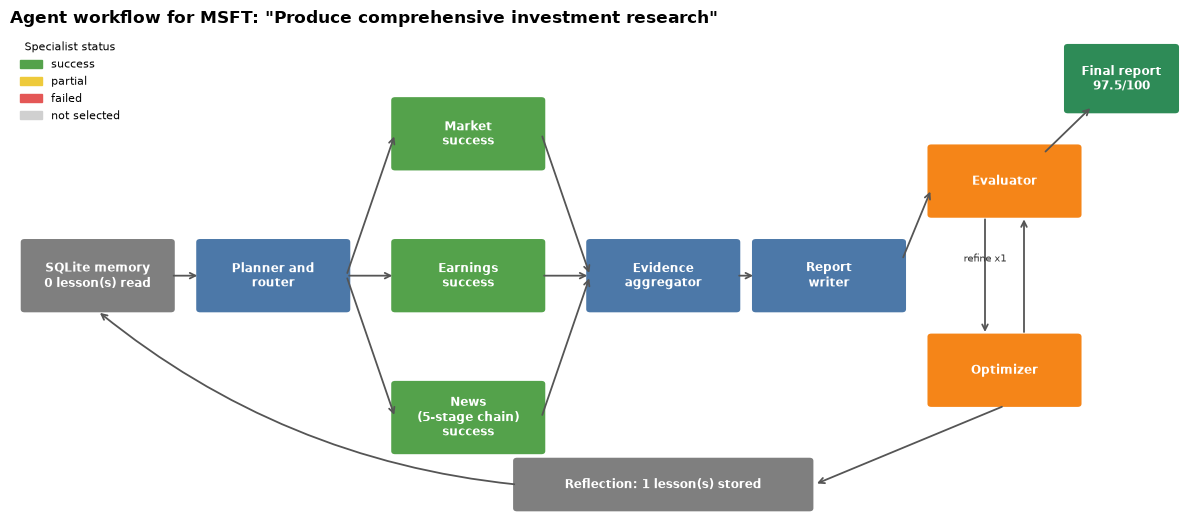

This run read 0 lesson(s) from memory, ran earnings, market, news, went through 1 refinement cycle(s), and stored 1 lesson(s) for later runs.

In [22]:
reflection = comprehensive.reflection
for field in ('successes', 'skipped_steps', 'failures', 'tool_problems', 'evidence_gaps', 'issues_fixed', 'issues_open', 'improvements'):
    print(field.replace('_', ' ').capitalize() + ':')
    for item in reflection[field] or ['none']:
        print('   -', item)
lessons = pd.DataFrame(reflection['lessons'])
if len(lessons):
    display(lessons[['memory_id', 'scope', 'symbol', 'lesson', 'hint', 'trigger']])
else:
    print('No lesson rule fired for this run.')
show(plot_agent_workflow(comprehensive), 'workflow_comprehensive', notes.workflow(comprehensive))

The reflection records the eight readability issues the refinement fixed and the three wording comments still open. One lesson rule fired: MEM-0001 asks later drafts to write amounts in billions and to state gaps as positive numbers. Its hint is report_guidance, so it reaches the report writer rather than the planner.

## 11. Learning across runs

This section isolates learning. Memory is cleared, and the same narrow question runs twice. The first run analyses price alone, so the evaluator finds that the price move has no explanation, and reflection stores a lesson for this symbol: run the news specialist for price questions. The second run starts from a fresh runtime, reads the lesson from the SQLite file, and its plan changes. Lessons only shape plans and writing; they never count as evidence.

In [23]:
memory.use_database(NOTEBOOK_MEMORY, reset=True)
QUESTION = 'Analyze one-year price performance'
run1 = rt.orchestrator.run('MSFT', QUESTION)

print('Run 1 lessons read      :', len(run1.memories_used))
print('Run 1 specialists       :', run1.selected_subagents)
driver_issues = [issue for h in run1.evaluation_history for issue in h['issues'] if issue['code'] == 'price_drivers_missing']
print('Evaluator on run 1      :', driver_issues[0]['message'] if driver_issues else 'no price-driver issue')
run1_lessons = pd.DataFrame(run1.reflection['lessons'])
display(run1_lessons[['memory_id', 'scope', 'symbol', 'tags', 'lesson', 'hint']])

Run 1 lessons read      : 0
Run 1 specialists       : ['market_agent']
Evaluator on run 1      : The price move is reported without its drivers, and the report does not say they were not analysed.


,memory_id,scope,symbol,tags,lesson,hint
0,MEM-0001,symbol,MSFT,[price],Price analysis of MSFT without recent news left the share-price move unexplained; include the news special...,{'require_subagents': ['news_agent']}
1,MEM-0002,general,NaN,[],First drafts printed raw figures or double negatives; write amounts in billions with one decimal and state...,{'report_guidance': 'Write amounts in billions with one decimal (for example USD 331.8 bn) and percentages...


In [24]:
# Read the lessons straight from the SQLite file with a new connection: they persist on disk.
with closing(sqlite3.connect(NOTEBOOK_MEMORY)) as connection:
    stored = pd.read_sql_query(
        'SELECT memory_id, scope, symbol, tags, lesson, hint, times_retrieved, times_applied FROM lessons ORDER BY memory_id',
        connection,
    )
display(stored)

,memory_id,scope,symbol,tags,lesson,hint,times_retrieved,times_applied
0,MEM-0001,symbol,MSFT,"[""price""]",Price analysis of MSFT without recent news left the share-price move unexplained; include the news special...,"{""require_subagents"": [""news_agent""]}",0,0
1,MEM-0002,general,NaN,[],First drafts printed raw figures or double negatives; write amounts in billions with one decimal and state...,"{""report_guidance"": ""Write amounts in billions with one decimal (for example USD 331.8 bn) and percentages...",0,0


In [25]:
memory.use_database(NOTEBOOK_MEMORY)  # reopen the same file, without clearing it
rt2 = build_runtime(settings=SETTINGS, allow_stubs=False)  # a fresh runtime; only the file carries the lessons
run2 = rt2.orchestrator.run('MSFT', QUESTION)

print('Run 2 lessons read      :', [item['memory_id'] for item in run2.memories_used])
print('Run 2 lessons applied   :', run2.plan.lessons_applied)
print('Run 2 specialists       :', run2.selected_subagents)
display(routing_table(run2.routing_log))
cited_memory = [source['id'] for source in run2.final_report['sources'] if source['id'].startswith('MEM-')]
print('Memory IDs cited as evidence in run 2:', cited_memory or 'none')

Run 2 lessons read      : ['MEM-0001', 'MEM-0002']
Run 2 lessons applied   : ['MEM-0001']
Run 2 specialists       : ['market_agent', 'news_agent']


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Retrieve and analyze MSFT's one-year price history, returns, volatility, and benchmark performance.",Provides the core quantitative price performance and volatility metrics requested.,0.95,success
1,SELECTED,news_agent,Gather news and catalyst events that explain the significant price movements observed over the one-year ti...,Explains the drivers behind the price trajectory as mandated by historical guidance for MSFT price queries.,0.90,success
2,skipped,earnings_agent,none,Financial statement and accounting analysis is not requested for a narrow one-year price performance quest...,0.80,skipped


Memory IDs cited as evidence in run 2: none


,label,specialists,initial,final,lessons_applied
0,Run 1,market_agent,94.5,94.5,[]
1,Run 2,"market_agent, news_agent",96.0,96.0,"[MEM-0001, MEM-0002]"


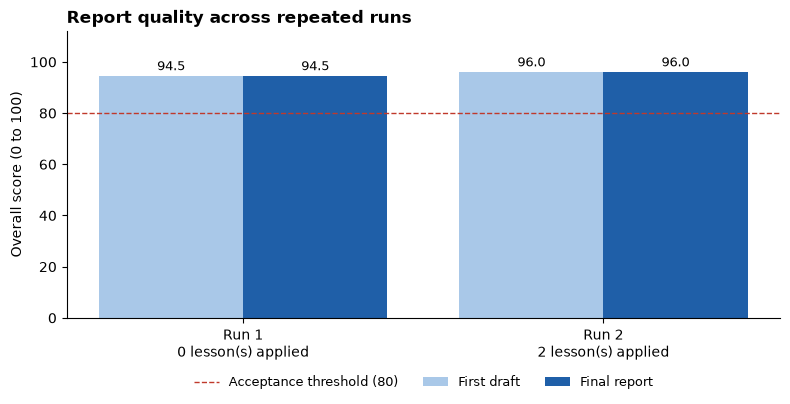

Run 1 went from 94.5 to 94.5 with 0 lesson(s) applied; Run 2 went from 96.0 to 96.0 with 2 lesson(s) applied. The first draft of the last run scored +1.5 points against the first run's.

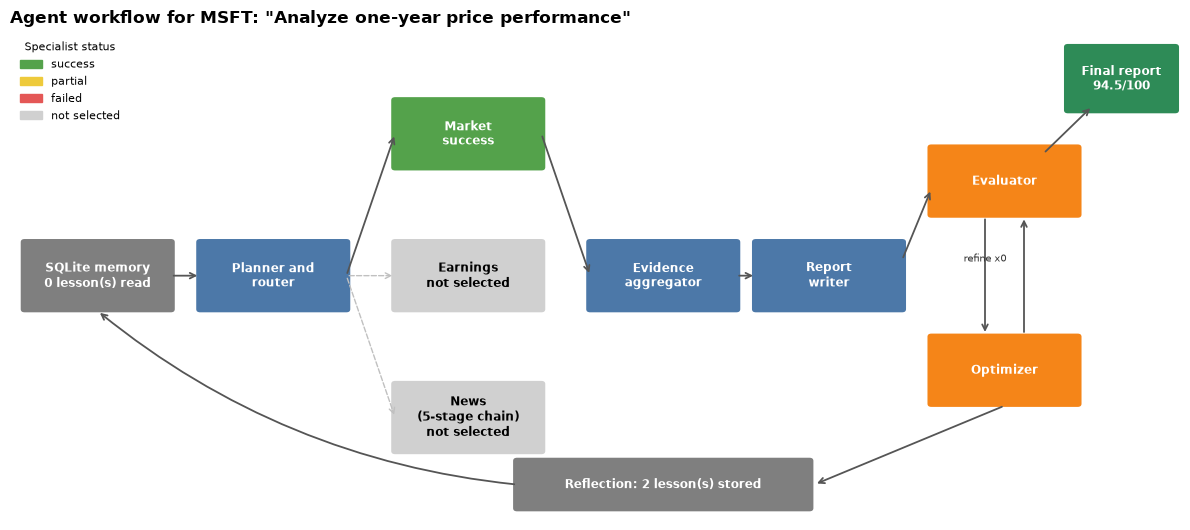

This run read 0 lesson(s) from memory, ran market and skipped earnings, news, went through 0 refinement cycle(s), and stored 2 lesson(s) for later runs.

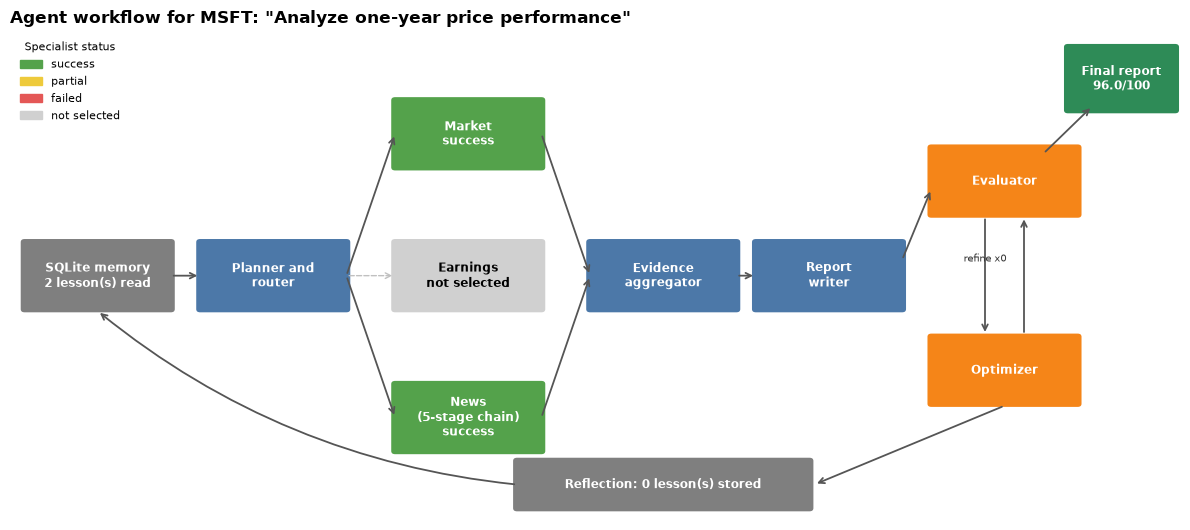

This run read 2 lesson(s) from memory, ran market, news and skipped earnings, went through 0 refinement cycle(s), and stored 0 lesson(s) for later runs.

In [26]:
runs = []
for label, state in (('Run 1', run1), ('Run 2', run2)):
    scores = [h['overall_score'] for h in state.evaluation_history]
    report = ResearchReport.from_dict(state.final_report)
    runs.append({
        'label': label,
        'specialists': ', '.join(state.selected_subagents),
        'initial': scores[0],
        'final': max(scores),
        'lessons_applied': list(dict.fromkeys(state.plan.lessons_applied + report.guidance_used)),
    })
display(pd.DataFrame(runs))
show(plot_quality_across_runs(runs, SETTINGS.quality_threshold), 'quality_across_runs', notes.quality_across_runs(runs))
show(plot_agent_workflow(run1), 'workflow_run1', notes.workflow(run1))
show(plot_agent_workflow(run2), 'workflow_run2', notes.workflow(run2))

Run 1 analysed price alone and scored 94.5. The evaluator noted that the price move had no stated drivers, and reflection stored MEM-0001 for MSFT price questions together with the writing lesson MEM-0002. Run 2 started from a fresh runtime and read both lessons from the SQLite file. Its plan added the news specialist, with the planner giving the earlier guidance as the reason, and the writer received the formatting lesson as guidance. Run 2's first draft scored 96.0, 1.5 points above run 1's, and no memory ID appears among its cited sources.

In [27]:
store = memory.get_store()
display(pd.DataFrame(store.runs())[['run_id', 'question', 'selected_subagents', 'initial_score', 'final_score', 'lessons_retrieved', 'lessons_applied']])
display(pd.DataFrame(store.usage()))

,run_id,question,selected_subagents,initial_score,final_score,lessons_retrieved,lessons_applied
0,8715c6a3,Analyze one-year price performance,[market_agent],94.5,94.5,[],[]
1,4d732aef,Analyze one-year price performance,"[market_agent, news_agent]",96.0,96.0,"[MEM-0001, MEM-0002]","[MEM-0001, MEM-0002]"


,id,run_id,memory_id,event,at
0,27,4d732aef,MEM-0001,retrieved,2026-10-17T20:07:21+00:00
1,28,4d732aef,MEM-0002,retrieved,2026-10-17T20:07:21+00:00
2,29,4d732aef,MEM-0001,applied,2026-10-17T20:07:21+00:00
3,30,4d732aef,MEM-0002,applied,2026-10-17T20:07:21+00:00


## 12. Summary and requirement checklist

The table below is computed from the runs in this notebook, so every entry points at output above rather than at a claim.

In [28]:
funnel = news.get('funnel', {})
selected_counts = [sum(1 for decision in routing if decision.selected) for routing in cases.values()]
checklist = [
    ('Planning', 'Section 1', f"{len(plan_state.plan.steps)} validated steps from the {plan_state.plan.planner_mode} planner"),
    ('Routing', 'Section 2', f"{min(selected_counts)} to {max(selected_counts)} specialists selected across {len(cases)} questions, each with a reason"),
    ('Dynamic tool use', 'Section 3', f"{len(tools_called(narrow))} data tools in the narrow run against {len(tools_called(comprehensive))} in the comprehensive run; memory reads and writes logged as tool calls"),
    ('Prompt chaining', 'Section 5', f"{funnel.get('ingested', 0)} headlines to {funnel.get('material_events', 0)} events through five stages"),
    ('Partial failure', 'Section 6', f"news failed; coverage {failed_run.aggregated['coverage']}; confidence {failed_report.confidence['level']}"),
    ('Evaluator-Optimizer', 'Sections 7 to 9', f"score {history[0]['overall_score']} to {best['overall_score']} over {len(history) - 1} refinement cycle(s)"),
    ('Self-reflection', 'Section 10', f"{len(reflection['issues_fixed'])} issue(s) fixed, {len(reflection['lessons'])} lesson(s) stored"),
    ('Learning across runs', 'Section 11', f"run 2 applied {runs[1]['lessons_applied']} and ran {runs[1]['specialists']}"),
]
display(pd.DataFrame(checklist, columns=['requirement', 'where', 'evidence from this execution']))
print('Files written for the comprehensive run:')
for label, path in comprehensive.output_files.items():
    print(f'   {label}: {pathlib.Path(path).relative_to(pathlib.Path.cwd())}')

,requirement,where,evidence from this execution
0,Planning,Section 1,3 validated steps from the llm planner
1,Routing,Section 2,"1 to 3 specialists selected across 6 questions, each with a reason"
2,Dynamic tool use,Section 3,4 data tools in the narrow run against 5 in the comprehensive run; memory reads and writes logged as tool ...
3,Prompt chaining,Section 5,123 headlines to 6 events through five stages
4,Partial failure,Section 6,"news failed; coverage {'earnings_agent': 'success', 'market_agent': 'success', 'news_agent': 'failed'}; co..."
5,Evaluator-Optimizer,Sections 7 to 9,score 95.5 to 97.5 over 1 refinement cycle(s)
6,Self-reflection,Section 10,"8 issue(s) fixed, 1 lesson(s) stored"
7,Learning across runs,Section 11,"run 2 applied ['MEM-0001', 'MEM-0002'] and ran market_agent, news_agent"


Files written for the comprehensive run:
   initial_report: outputs/reports/MSFT_8b8b0d9d_initial.md
   final_report: outputs/reports/MSFT_8b8b0d9d_final.md
   run_log: outputs/logs/MSFT_8b8b0d9d.json


In this execution the agent planned each request, routed it to the specialists it needed, and called only the tools each plan step allowed. The news chain reduced 123 headlines to six cited events, the evaluator found unformatted figures and a double negative in a first draft that scored 95.5, and one refinement cycle raised the report to 97.5 without losing a citation. Reflection turned those problems into a writing lesson, and in the learning demonstration a lesson stored by the first run added the news specialist to the second run's plan.

News analysis reads headlines rather than full articles, and its labels are language-model judgements. Financial analysis uses annual statements, so quarters after the fiscal year end are not reflected. Prices are adjusted closes from one provider, and the benchmark is the broad market rather than the company's sector. Clarity is partly an LLM judgement; the other seven criteria are rule-based checks of citations, numbers and coverage, which measure whether claims are supported rather than whether the reasoning is sound. None of this is investment advice.

## Team Work Split

| Vivek Shivaram | Vivek Singh | Piyush Vishwakarma |
|---|---|---|
| <ul><li>Define shared state, plan, step, routing, and specialist input/output schemas.</li><li>Interpret questions, decompose dependencies and completion criteria, include relevant lessons, and validate plans.</li><li>Select only the Market, Earnings, and News specialists relevant to each question.</li><li>Maintain specialist and tool registries; record selected and skipped agents with reasons and enforce task tool permissions.</li><li>Execute plan steps in dependency order while maintaining state and logging tool calls and outcomes.</li><li>Aggregate evidence, handle partial failures, and connect specialist outputs to the report pipeline and notebook.</li><li>Contribute relevant outputs to the report and Section 12's final summary and requirement checklist.</li></ul> | <br><ul><li>Connect and normalize company profiles, adjusted price histories, benchmark prices, and financial statements.</li><li>Implement reproducible market and earnings analysis with evidence-backed findings, risks, and limitations.</li><li>Retrieve company headlines from Yahoo Finance and Google News RSS; deduplicate and filter for relevance.</li><li>Implement ingest, preprocess, classify, extract, and summarize stages; validate and preserve intermediate outputs.</li><li>Add caching, retries, timeouts, and validation; turn missing or failed data into clear warnings.</li><li>Integrate optional FRED macro series and SEC filings, and provide visualization-ready specialist outputs.</li><li>Contribute relevant outputs to the report and Section 12's final summary and requirement checklist.</li></ul> | <ul><li>Generate evidence-cited reports that distinguish facts, interpretations, confidence, and limitations.</li><li>Implement rubric-based evaluation with criterion scores, issues, and corrective actions.</li><li>Optimize weak sections while preserving supported claims and citations; stop at the quality threshold or cycle limit.</li><li>Reflect on run successes, failures, tool problems, evidence gaps, and fixed or open issues.</li><li>Persist and retrieve lessons in SQLite; demonstrate second-run learning without treating memory as evidence.</li><li>Create charts and workflow visualizations with concise interpretations throughout the notebook.</li><li>Contribute relevant outputs to the report and Section 12's final summary and requirement checklist.</li></ul> |